# Hanging Sphere — QuESo vs NN: Local Ke and Displacement

Compares, on the hanging sphere geometry:
1. **Local stiffness matrices** of trimmed cells — QuESo integration vs NN prediction
2. **Global displacement** — QuESo pipeline vs Hybrid (classic inside + NN trimmed)

In [1]:
from pathlib import Path
import os, sys
import numpy as np
import torch

# ── paths ──────────────────────────────────────────────────────────────────
root = Path.cwd().resolve()
while root != root.parent and not (root / 'clean_simulation').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

queso_python_path = root / 'QuESo' / 'out' / 'install' / 'win'
if queso_python_path.exists() and str(queso_python_path) not in sys.path:
    sys.path.insert(0, str(queso_python_path))
if os.name == 'nt' and hasattr(os, 'add_dll_directory') and queso_python_path.exists():
    os.add_dll_directory(str(queso_python_path))

# ── build case ─────────────────────────────────────────────────────────────
from clean_simulation.case import build_example_case

out_dir = root / 'clean_simulation' / 'outputs' / 'displacements'
out_dir.mkdir(parents=True, exist_ok=True)

OVERRIDES = {
    "material": {"E": 1e6},
    "loads":    {"gravity": [0.0, 0.0, -98.1]},
}

case = build_example_case(
    workspace_root=root,
    work_dir=out_dir,
    queso_python_path=queso_python_path,
    device='cpu',
    overrides=OVERRIDES,
)
print(f'Grid resolution : {case.grid.resolution}')
print(f'h_ref (dx)      : {case.grid.dx:.6f}')
print(f'E               : {case.material.E:.2e}')
print(f'gravity         : {case.config["loads"]["gravity"]}')

# ── load NN — pick the best available checkpoint ────────────────────────────
ckpt_dir = root / 'clean_simulation' / 'outputs' / 'checkpoints'

# Prefer later stages; fall back to earlier ones if not yet trained
for stage_name in ['cutcellnet_stage13.pt']:
    ckpt_path = ckpt_dir / stage_name
    if ckpt_path.exists():
        print(f'Using checkpoint: {stage_name}')
        break
else:
    raise FileNotFoundError('No stage checkpoint found in ' + str(ckpt_dir))

from clean_simulation.nn_runtime import load_nn_engine
nn_engine = load_nn_engine(checkpoint_path=ckpt_path, device='cpu', dtype='float32')
print('NN engine loaded.')


[CASE BUILD] Configuring legacy imports and loading libraries...
[CASE BUILD] Imports took 0.0230 seconds.
[CASE BUILD] Geometry + mesh setup took 0.0129 seconds.
[CASE BUILD] QuESo execution and IP extraction took 1.6321 seconds.
[CASE BUILD] Total case build time: 1.6823 seconds.
Grid resolution : [30, 30, 30]
h_ref (dx)      : 1.000000
E               : 1.00e+06
gravity         : [0.0, 0.0, -98.1]
Using checkpoint: cutcellnet_stage13.pt


C:\Users\z0058p1u\Documents\code\clean_simulation\internal_nn_runtime\cutcell_ml\model.py:689: TracerWarning: Iterating over a tensor might cause the trace to be incorrect. Passing a tensor of different shape won't change the number of iterations executed (and might lead to errors or silently give incorrect results).
  rows, cols = torch.triu_indices(


NN engine loaded.


In [74]:
# ── 1. Identify trimmed cells and compute QuESo Ke ─────────────────────────
from clean_simulation.bootstrap import configure_legacy_imports
configure_legacy_imports(root)

from internal_fem_kernel.assembly.stiffness import StiffnessAssembly
from internal_fem_kernel.classification import Classification

inside, partial, _ = Classification.classify_sdf(case.volume, case.grid, device='cpu')
partial_flat = partial.reshape(-1).nonzero(as_tuple=True)[0].cpu()

# Map each integration point to its grid cell flat index.
# case.ips stores UVW coordinates in [0,1]^3; convert to world XYZ first.
ips_np  = np.asarray(case.ips)          # (N_ips, 4)  [U, V, W, Weight]
b0_arr  = np.array(case.grid.bounds[0])
b1_arr  = np.array(case.grid.bounds[1])
ip_uvw  = ips_np[:, :3]
# Apply the same UVW→XYZ transform used inside compute_element_matrices_from_queso_points
ip_xyz  = b0_arr + ip_uvw * (b1_arr - b0_arr)

dx_arr  = np.array([case.grid.dx, case.grid.dy, case.grid.dz])
_, ny, nz = case.grid.resolution
ip_ijk  = np.floor((ip_xyz - b0_arr) / dx_arr).astype(int).clip(0)
ip_flat = ip_ijk[:, 0] * ny * nz + ip_ijk[:, 1] * nz + ip_ijk[:, 2]

partial_set  = set(partial_flat.tolist())
trimmed_mask = np.array([f in partial_set for f in ip_flat])
ips_trimmed  = ips_np[trimmed_mask]

print(f'Trimmed cells : {len(partial_flat)}')
print(f'Trimmed IPs   : {trimmed_mask.sum()} / {len(ips_np)}')

# QuESo Ke — returns a (N, 24, 24) tensor directly
ke_queso, queso_active = StiffnessAssembly.compute_element_matrices_from_queso_points(
    grid=case.grid, material=case.material,
    ips=ips_trimmed, poly_order=case.poly_order, device='cpu',
)
ke_queso = ke_queso.double()   # (N, 24, 24)
print(f'QuESo Ke : {ke_queso.shape}')

# ── 2. NN Ke for the same trimmed cells ────────────────────────────────────
from clean_simulation.internal_nn_runtime.cutcell_bridge import (
    prepare_nn_inputs, compute_nn_cutcell_stiffness,
)

d_norm, nu_cut, h_ref = prepare_nn_inputs(
    grid=case.grid, volume=case.volume,
    partial_indices=queso_active,
    material=case.material, poly_order=case.poly_order,
)
ke_nn_list, _ = compute_nn_cutcell_stiffness(
    d_cut=d_norm, nu_cut=nu_cut, nn_engine=nn_engine,
    material=case.material, partial_indices=queso_active, h_ref=h_ref,
)
def project_out_rigid_modes(k, n_modes=6):
    k_sym = 0.5*(k + k.transpose(-1,-2))
    evals, evecs = torch.linalg.eigh(k_sym)
    evals_fixed = evals.clone()
    evals_fixed[..., :n_modes] = 0.0          # force rigid-body eigenvalues to exactly zero
    k_fixed = evecs @ torch.diag_embed(evals_fixed) @ evecs.transpose(-1,-2)
    return k_fixed

# stack the list into one batched tensor, run the (now batched) function ONCE,
# then unbind back into a list — same names, same function, just no python loop
ke_nn_stacked = torch.stack(ke_nn_list, dim=0)     # (T, n, n)
ke_nn_fixed_stacked = project_out_rigid_modes(ke_nn_stacked, n_modes=6)
ke_nn_list = list(torch.unbind(ke_nn_fixed_stacked, dim=0))


ke_nn = torch.stack(ke_nn_list).double()     # (N, 24, 24)
print(f'NN Ke    : {ke_nn.shape}')

# ── 3. Local Ke comparison ─────────────────────────────────────────────────
rel_err = (ke_queso - ke_nn).norm(dim=(-2, -1)) / ke_queso.norm(dim=(-2, -1))



print(f'\n── Local Ke relative Frobenius error (NN vs QuESo) ──')
print(f'  mean   : {rel_err.mean():.4f}')
print(f'  median : {rel_err.median():.4f}')
print(f'  p95    : {torch.quantile(rel_err, 0.95):.4f}')
print(f'  max    : {rel_err.max():.4f}')

Trimmed cells : 1064
Trimmed IPs   : 27325 / 62533
QuESo Ke : torch.Size([1016, 24, 24])
NN Ke    : torch.Size([1016, 24, 24])

── Local Ke relative Frobenius error (NN vs QuESo) ──
  mean   : 0.0145
  median : 0.0098
  p95    : 0.0407
  max    : 0.0657


{'E': 1000000.0, 'nu': 0.3, 'density': 7850.0}

In [75]:
# ── 4. Per-class error distribution ─────────────────────────────────────────
from clean_simulation.internal_nn_runtime.cutcell_ml.model import compute_vectorized_class_label

# d_norm is the NN's actual input (same ordering as ke_nn/ke_queso/queso_active),
# so this gives the class label exactly as the model would have seen it.
d_for_class = d_norm if torch.is_tensor(d_norm) else torch.as_tensor(d_norm)
cls_local = compute_vectorized_class_label(d_for_class.float())

n_classes = 15
counts = torch.bincount(cls_local, minlength=n_classes)

print(f'\n── Per-class relative Frobenius error (NN vs QuESo), {len(rel_err)} trimmed cells ──')
print(f"{'class':>6} {'n':>8} {'mean':>9} {'median':>9} {'std':>9} {'p95':>9} {'max':>9} {'se':>9}")
print("-" * 68)

rows = []
for c in range(n_classes):
    mask = (cls_local == c)
    n_c = int(mask.sum())
    if n_c == 0:
        print(f"{c:>6} {0:>8} {'--':>9} {'--':>9} {'--':>9} {'--':>9} {'--':>9} {'--':>9}")
        continue
    err_c = rel_err[mask]
    se = (err_c.std() / (n_c ** 0.5)).item() if n_c > 1 else float('nan')
    rows.append((c, n_c, err_c.mean().item(), err_c.median().item(),
                 err_c.std().item() if n_c > 1 else 0.0,
                 torch.quantile(err_c, 0.95).item(), err_c.max().item(), se))
    print(f"{c:>6} {n_c:>8} {err_c.mean():>9.4f} {err_c.median():>9.4f} "
          f"{(err_c.std() if n_c>1 else 0.0):>9.4f} {torch.quantile(err_c,0.95):>9.4f} "
          f"{err_c.max():>9.4f} {se:>9.4f}")

# Sorted by mean error, worst first -- the actual "which classes fail most" answer
print(f"\n── Ranked worst-to-best by mean error ──")
for c, n_c, mean_e, median_e, std_e, p95_e, max_e, se in sorted(rows, key=lambda r: -r[2]):
    flag = "  <- low n, noisy" if n_c < 30 else ""
    print(f"  class {c:2d}: mean={mean_e:.4f}  n={n_c}{flag}")


── Per-class relative Frobenius error (NN vs QuESo), 1016 trimmed cells ──
 class        n      mean    median       std       p95       max        se
--------------------------------------------------------------------
     0        0        --        --        --        --        --        --
     1      272    0.0153    0.0109    0.0155    0.0449    0.0607    0.0009
     2      224    0.0194    0.0160    0.0142    0.0458    0.0657    0.0009
     3      112    0.0178    0.0148    0.0139    0.0469    0.0572    0.0013
     4       80    0.0088    0.0087    0.0039    0.0161    0.0227    0.0004
     5      128    0.0134    0.0128    0.0074    0.0259    0.0280    0.0007
     6        0        --        --        --        --        --        --
     7        0        --        --        --        --        --        --
     8        0        --        --        --        --        --        --
     9       40    0.0087    0.0079    0.0043    0.0179    0.0213    0.0007
    10       48    

In [76]:
# ── What distinguishes the worst classes (2,3,1,13) from the best (10,11)? ────
from clean_simulation.internal_nn_runtime.cutcell_ml.classification_utils import _canonicalize_case_mask, MASK_TO_CLASS

# Recover one representative mask per class, and how many "in" corners it has
mask_to_class = {}
for m in range(256):
    c = MASK_TO_CLASS[_canonicalize_case_mask(m)]
    mask_to_class.setdefault(c, []).append(m)

def popcount(m): return bin(m).count("1")

for c in [2, 3, 1, 13, 5, 4, 9, 10, 11]:
    masks = mask_to_class[c]
    pop_counts = sorted(set(popcount(m) for m in masks))
    print(f"class {c:2d}: {len(masks)} equiv. masks, corner-in counts: {pop_counts}, example mask: {masks[0]:#010b}")

class  2: 24 equiv. masks, corner-in counts: [2, 6], example mask: 0b00000011
class  3: 24 equiv. masks, corner-in counts: [2, 6], example mask: 0b00000110
class  1: 16 equiv. masks, corner-in counts: [1, 7], example mask: 0b00000001
class 13: 6 equiv. masks, corner-in counts: [4], example mask: 0b00111100
class  5: 6 equiv. masks, corner-in counts: [4], example mask: 0b00001111
class  4: 48 equiv. masks, corner-in counts: [3, 5], example mask: 0b00000111
class  9: 48 equiv. masks, corner-in counts: [3, 5], example mask: 0b00011001
class 10: 12 equiv. masks, corner-in counts: [4], example mask: 0b00011011
class 11: 12 equiv. masks, corner-in counts: [4], example mask: 0b00011101


c:\Users\z0058p1u\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a, func=_nanmedian, keepdims=keepdims,
c:\Users\z0058p1u\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


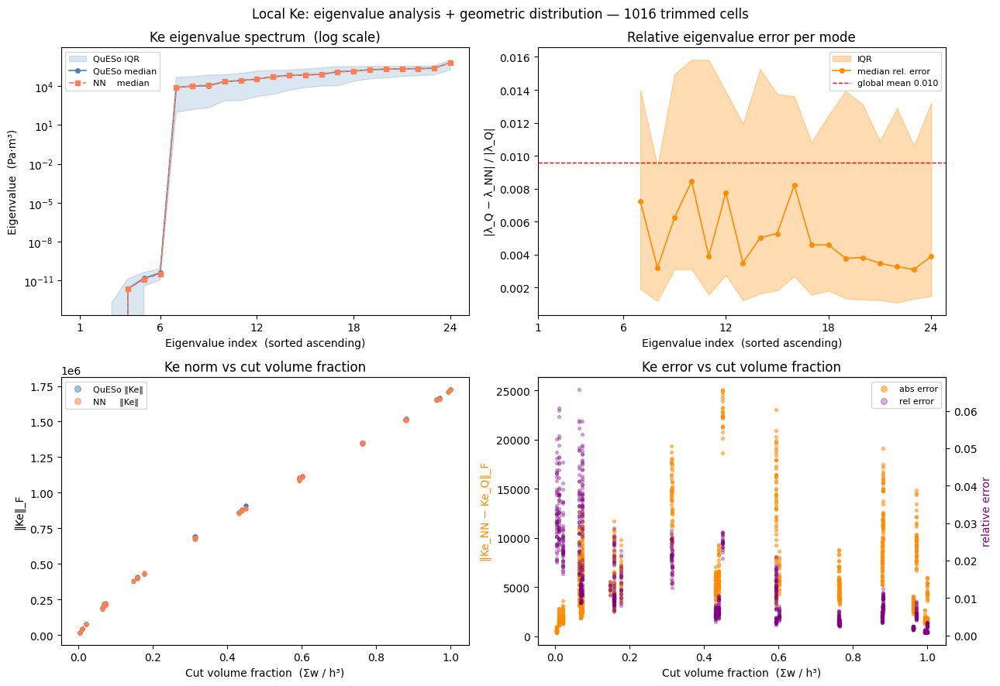

Eigenvalue relative error  (non-trivial modes, |λ| > 1% max):
  mean   : 0.0096
  median : 0.0046
  max    : 0.0944
  mode 1 (stiffest): 0.0039    mode 24 (softest non-zero): 0.0072


In [77]:
import matplotlib.pyplot as plt

abs_ke_err_np = (ke_queso - ke_nn).norm(dim=(-2, -1)).numpy()
rel_ke_err_np = rel_err.numpy()
ke_queso_norm = ke_queso.norm(dim=(-2, -1)).numpy()
ke_nn_norm    = ke_nn   .norm(dim=(-2, -1)).numpy()

# ── Eigenvalues of every trimmed-cell Ke  (symmetric SPD → eigvalsh) ──────────
eigvals_q  = torch.linalg.eigvalsh(ke_queso).numpy()   # (N, 24) sorted ascending
eigvals_nn = torch.linalg.eigvalsh(ke_nn)   .numpy()

# ── Cut volume fraction ───────────────────────────────────────────────────────
q_active_np      = queso_active.cpu().numpy()
ny_, nz_         = int(case.grid.resolution[1]), int(case.grid.resolution[2])
trimmed_ip_flat  = ip_flat[trimmed_mask]
v_grid_phys      = float(np.prod(b1_arr - b0_arr))
physical_weights = ips_trimmed[:, 3] * v_grid_phys
cell_volume      = float(case.grid.dx ** 3)

cut_vol_fraction = np.zeros(len(q_active_np))
for pos, elem_flat in enumerate(q_active_np):
    cut_vol_fraction[pos] = physical_weights[trimmed_ip_flat == elem_flat].sum()
cut_vol_fraction /= cell_volume

# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Local Ke: eigenvalue analysis + geometric distribution — 1016 trimmed cells', fontsize=12)

# ── Row 1: eigenvalue study ────────────────────────────────────────────────────
idx = np.arange(1, 25)

# Panel 1,0 — mean eigenvalue spectrum: QuESo vs NN
ax = axes[0, 0]
med_q  = np.median(eigvals_q,  axis=0)
med_nn = np.median(eigvals_nn, axis=0)
p25_q  = np.percentile(eigvals_q,  25, axis=0)
p75_q  = np.percentile(eigvals_q,  75, axis=0)
ax.fill_between(idx, p25_q, p75_q, color='steelblue', alpha=0.2, label='QuESo IQR')
ax.semilogy(idx, med_q,  'o-', color='steelblue', ms=4, lw=1.2, label='QuESo median')
ax.semilogy(idx, med_nn, 's--', color='coral',     ms=4, lw=1.2, label='NN    median')
ax.set_xlabel('Eigenvalue index  (sorted ascending)')
ax.set_ylabel('Eigenvalue  (Pa·m³)')
ax.set_title('Ke eigenvalue spectrum  (log scale)')
ax.legend(fontsize=8)
ax.set_xticks([1, 6, 12, 18, 24])

# Panel 1,1 — relative eigenvalue error per index
ax = axes[0, 1]
# Only consider non-trivial eigenvalues (|λ_Q| > 1% of max)
eps    = 1e-2 * np.abs(eigvals_q).max()
mask2d = np.abs(eigvals_q) > eps                      # (N, 24) bool
rel_eig_err = np.where(mask2d,
                        np.abs(eigvals_q - eigvals_nn) / (np.abs(eigvals_q) + 1e-30),
                        np.nan)                        # (N, 24)

med_rel = np.nanmedian(rel_eig_err, axis=0)
p25_rel = np.nanpercentile(rel_eig_err, 25, axis=0)
p75_rel = np.nanpercentile(rel_eig_err, 75, axis=0)
ax.fill_between(idx, p25_rel, p75_rel, color='darkorange', alpha=0.3, label='IQR')
ax.plot(idx, med_rel, 'o-', color='darkorange', ms=4, lw=1.2, label='median rel. error')
ax.axhline(np.nanmean(rel_eig_err), color='red', ls='--', lw=1, label=f'global mean {np.nanmean(rel_eig_err):.3f}')
ax.set_xlabel('Eigenvalue index  (sorted ascending)')
ax.set_ylabel('|λ_Q − λ_NN| / |λ_Q|')
ax.set_title('Relative eigenvalue error per mode')
ax.legend(fontsize=8)
ax.set_xticks([1, 6, 12, 18, 24])

# ── Row 2: Ke norm vs cut volume fraction (unchanged) ─────────────────────────
ax = axes[1, 0]
ax.scatter(cut_vol_fraction, ke_queso_norm, s=8, alpha=0.5, color='steelblue', label='QuESo ‖Ke‖')
ax.scatter(cut_vol_fraction, ke_nn_norm,    s=8, alpha=0.5, color='coral',     label='NN     ‖Ke‖')
ax.set_xlabel('Cut volume fraction  (Σw / h³)')
ax.set_ylabel('‖Ke‖_F')
ax.set_title('Ke norm vs cut volume fraction')
ax.legend(fontsize=8, markerscale=2)

ax = axes[1, 1]
ax.scatter(cut_vol_fraction, abs_ke_err_np, s=8, alpha=0.5, color='darkorange', label='abs error')
ax2 = ax.twinx()
ax2.scatter(cut_vol_fraction, rel_ke_err_np, s=8, alpha=0.3, color='purple', label='rel error')
ax.set_xlabel('Cut volume fraction  (Σw / h³)')
ax.set_ylabel('‖Ke_NN − Ke_Q‖_F', color='darkorange')
ax2.set_ylabel('relative error', color='purple')
ax.set_title('Ke error vs cut volume fraction')
lines1, labs1 = ax.get_legend_handles_labels()
lines2, labs2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labs1 + labs2, fontsize=8, markerscale=2)

fig.tight_layout()
plt.show()

print(f'Eigenvalue relative error  (non-trivial modes, |λ| > 1% max):')
print(f'  mean   : {np.nanmean(rel_eig_err):.4f}')
print(f'  median : {np.nanmedian(rel_eig_err):.4f}')
print(f'  max    : {np.nanmax(rel_eig_err):.4f}')
print(f'  mode 1 (stiffest): {med_rel[-1]:.4f}  '
      f'  mode 24 (softest non-zero): {med_rel[np.where(~np.isnan(med_rel))[0][0]]:.4f}')

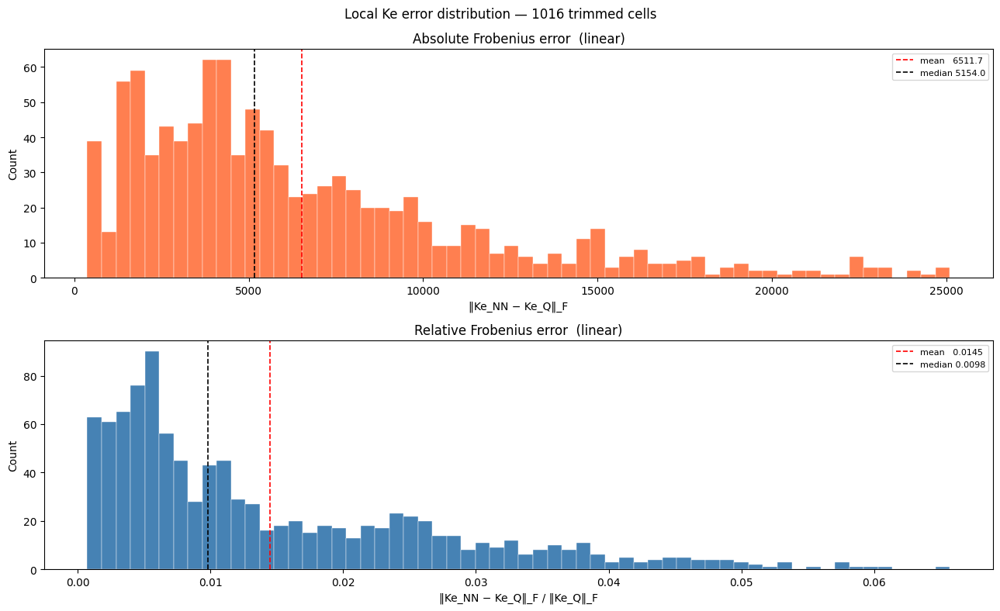

Absolute: min=370.3  mean=6511.7  median=5154.0  max=25104.8
Relative: min=0.0007  mean=0.0145  median=0.0098  max=0.0657


In [78]:
import matplotlib.pyplot as plt

abs_err_np = (ke_queso - ke_nn).norm(dim=(-2, -1)).numpy()
rel_err_np = rel_err.numpy()

fig, axes = plt.subplots(2, figsize=(13, 8))
fig.suptitle('Local Ke error distribution — 1016 trimmed cells', fontsize=12)

ax = axes[0]
ax.hist(abs_err_np, bins=60, color='coral', edgecolor='white', lw=0.3)
ax.axvline(abs_err_np.mean(),            color='red',   ls='--', lw=1.2, label=f'mean   {abs_err_np.mean():.1f}')
ax.axvline(float(np.median(abs_err_np)), color='black', ls='--', lw=1.2, label=f'median {float(np.median(abs_err_np)):.1f}')
ax.set_xlabel('‖Ke_NN − Ke_Q‖_F')
ax.set_ylabel('Count')
ax.set_title('Absolute Frobenius error  (linear)')
ax.legend(fontsize=8)



ax = axes[1]
ax.hist(rel_err_np, bins=60, color='steelblue', edgecolor='white', lw=0.3)
ax.axvline(rel_err_np.mean(),            color='red',   ls='--', lw=1.2, label=f'mean   {rel_err_np.mean():.4f}')
ax.axvline(float(np.median(rel_err_np)), color='black', ls='--', lw=1.2, label=f'median {float(np.median(rel_err_np)):.4f}')
ax.set_xlabel('‖Ke_NN − Ke_Q‖_F / ‖Ke_Q‖_F')
ax.set_ylabel('Count')
ax.set_title('Relative Frobenius error  (linear)')
ax.legend(fontsize=8)



fig.tight_layout()
plt.show()

print(f'Absolute: min={abs_err_np.min():.1f}  mean={abs_err_np.mean():.1f}  '
      f'median={float(np.median(abs_err_np)):.1f}  max={abs_err_np.max():.1f}')
print(f'Relative: min={rel_err_np.min():.4f}  mean={rel_err_np.mean():.4f}  '
      f'median={float(np.median(rel_err_np)):.4f}  max={rel_err_np.max():.4f}')

In [117]:
import time
from internal_fem_kernel.runtime.assembly_ops import assemble_stiffness_base, assemble_force_base
from internal_fem_kernel.runtime.solver import solve_with_nitsche

# ── QuESo Ke for ALL elements (inside + trimmed) ────────────────────────────
t0 = time.perf_counter()
ke_all_queso, active_all = StiffnessAssembly.compute_element_matrices_from_queso_points(
    grid=case.grid, material=case.material,
    ips=np.asarray(case.ips),
    poly_order=case.poly_order, device='cpu',
)
print(f'QuESo Ke (all): {ke_all_queso.shape}  active={len(active_all)}  ({time.perf_counter()-t0:.1f}s)')

# ── Hybrid Ke: clone QuESo Ke, swap trimmed cells with NN Ke ─────────────────
n_cells_total = int(np.prod(case.grid.resolution))
flat_to_pos = torch.full((n_cells_total,), -1, dtype=torch.int64)
flat_to_pos[active_all.cpu()] = torch.arange(len(active_all), dtype=torch.int64)
trimmed_positions = flat_to_pos[queso_active.cpu()]
assert (trimmed_positions >= 0).all()

ke_all_hybrid = ke_all_queso.clone()
ke_all_hybrid[trimmed_positions] = ke_nn
print(f'Hybrid Ke: swapped {len(trimmed_positions)} trimmed cells')

# ── Assemble K ───────────────────────────────────────────────────────────────
t0 = time.perf_counter()
ke_queso_list_all  = [ke_all_queso[i]  for i in range(len(ke_all_queso))]
ke_hybrid_list_all = [ke_all_hybrid[i] for i in range(len(ke_all_hybrid))]

K_queso  = assemble_stiffness_base(ke_list=ke_queso_list_all,  active_indices=active_all, grid=case.grid, poly_order=case.poly_order, device='cpu')
K_hybrid = assemble_stiffness_base(ke_list=ke_hybrid_list_all, active_indices=active_all, grid=case.grid, poly_order=case.poly_order, device='cpu')
print(f'K assembly : {time.perf_counter()-t0:.1f}s')

# ── Force vector ─────────────────────────────────────────────────────────────
t0 = time.perf_counter()
F = assemble_force_base(grid=case.grid, active_indices=active_all, ips=case.ips, config=case.config, poly_order=case.poly_order).cpu()
print(f'Force      : {time.perf_counter()-t0:.1f}s')

# ── Solve — capture k_global (K + Nitsche) for correct residual check ────────
t0 = time.perf_counter()
u_q_nodes, u_q_vec, _, _, nitsche_sets, K_q_full = solve_with_nitsche(
    grid=case.grid, material=case.material, config=case.config,
    top_mesh=case.top_mesh, active_indices=active_all,
    poly_order=case.poly_order, g_order=case.g_order,
    k_base=K_queso, f_base=F, device='cpu',
)
print(f'Solve QuESo : {time.perf_counter()-t0:.1f}s')

t0 = time.perf_counter()
u_h_nodes, u_h_vec, _, _, _, K_h_full = solve_with_nitsche(
    grid=case.grid, material=case.material, config=case.config,
    top_mesh=case.top_mesh, active_indices=active_all,
    poly_order=case.poly_order, g_order=case.g_order,
    k_base=K_hybrid, f_base=F, device='cpu',
    precomputed_nitsche_sets=nitsche_sets,
)
print(f'Solve Hybrid: {time.perf_counter()-t0:.1f}s')

u_q = u_q_vec.double().cpu()
u_h = u_h_vec.double().cpu()




QuESo Ke (all): torch.Size([2320, 24, 24])  active=2320  (5.8s)
Hybrid Ke: swapped 1016 trimmed cells
K assembly : 0.1s
Force      : 0.0s
Solve QuESo : 4.6s
Solve Hybrid: 9.3s


In [120]:
# did ke_all_hybrid get rebuilt from the corrected ke_nn_list?
ke_nn_fixed_stacked = torch.stack(ke_nn_list, dim=0)   # your corrected version
ke_all_hybrid_v2 = ke_all_queso.clone()
ke_all_hybrid_v2[trimmed_positions] = ke_nn_fixed_stacked

# sanity: did anything actually change vs the old hybrid?
print("max abs diff old vs new hybrid at trimmed cells:",
      (ke_all_hybrid_v2[trimmed_positions] - ke_all_hybrid[trimmed_positions]).abs().max().item())

max abs diff old vs new hybrid at trimmed cells: 0.0


In [125]:
bad_mask = (min_eig_nn.numpy() < -1e-6)
print("bad cell count (recomputed):", bad_mask.sum())   # should be 1015 per your earlier result
bad_cell_ids = set(cell_ids[bad_mask].tolist())
print("bad_cell_ids size:", len(bad_cell_ids))

bad cell count (recomputed): 0
bad_cell_ids size: 0


In [127]:
# adjust once you see the real structure — likely need to concatenate boundary_elems across all Nitsche calls
nitsche_touched_cells = set()
for entry in nitsche_sets:  # or nitsche_sets.values(), or nitsche_sets['boundary_elems'], etc.
    elems = entry[-1] if isinstance(entry, (tuple, list)) else entry
    nitsche_touched_cells.update(np.asarray(elems).tolist())
print("nitsche-touched cells (corrected):", len(nitsche_touched_cells))

nitsche-touched cells (corrected): 4


In [128]:
# recompute from the pristine ke_nn — reload/recompute it if ke_nn itself was reassigned in place
ke_nn_sym_orig = 0.5 * (ke_nn_original + ke_nn_original.transpose(-1, -2))
eigs_orig = torch.linalg.eigvalsh(ke_nn_sym_orig)
min_eig_nn = eigs_orig[:, :6].min(dim=1).values     # or eigs_orig.min(dim=1).values for global min
cond_nn = eigs_orig.amax(dim=1) / eigs_orig.amin(dim=1).clamp(min=1e-30)

bad_mask = (min_eig_nn.numpy() < -1e-6)
print("bad cell count:", bad_mask.sum())   # should be back to 1015

NameError: name 'ke_nn_original' is not defined

In [80]:
ke_queso_trim = ke_all_queso[trimmed_positions]   # (T, ndof, ndof)

# symmetry
sym_err = (ke_nn - ke_nn.transpose(-1,-2)).abs().amax(dim=(-1,-2))
print("max asymmetry in ke_nn:", sym_err.max().item())

# positive semi-definiteness / conditioning
eigs_nn    = torch.linalg.eigvalsh(0.5*(ke_nn + ke_nn.transpose(-1,-2)))
eigs_queso = torch.linalg.eigvalsh(0.5*(ke_queso_trim + ke_queso_trim.transpose(-1,-2)))

min_eig_nn    = eigs_nn.min(dim=1).values
min_eig_queso = eigs_queso.min(dim=1).values
cond_nn       = eigs_nn.amax(dim=1) / eigs_nn.amin(dim=1).clamp(min=1e-30)

print("negative/near-zero eigenvalues in ke_nn:", (min_eig_nn < -1e-8).sum().item())
print("worst condition number (ke_nn):", cond_nn.max().item())

# relative Frobenius difference per trimmed cell — flags which cells disagree most
diff_norm = (ke_nn - ke_queso_trim).flatten(1).norm(dim=1)
ref_norm  = ke_queso_trim.flatten(1).norm(dim=1).clamp(min=1e-30)
rel_diff  = diff_norm / ref_norm
worst = torch.argsort(rel_diff, descending=True)[:15]
print("worst-agreement trimmed cells (rel diff):", rel_diff[worst])
print("their cell ids:", torch.as_tensor(queso_active)[worst])

max asymmetry in ke_nn: 4.3655745685100555e-11
negative/near-zero eigenvalues in ke_nn: 0
worst condition number (ke_nn): 1.2513898871276147e+36
worst-agreement trimmed cells (rel diff): tensor([0.0657, 0.0607, 0.0601, 0.0584, 0.0575, 0.0572, 0.0571, 0.0553, 0.0537,
        0.0532, 0.0527, 0.0525, 0.0509, 0.0508, 0.0504], dtype=torch.float64)
their cell ids: tensor([20324, 15802, 14627, 11927,  6675,  7639, 20325, 11272, 14078, 20292,
        15072, 19451, 19484, 11473, 19369])


In [81]:
coords = case.grid.node_coordinates().cpu().numpy()

In [82]:

err = (u_h_nodes - u_q_nodes)              # (N, 3) nodal
err_mag = err.norm(dim=1).cpu().numpy()


order = np.argsort(err_mag)
worst = order[-20:][::-1]
best_nonzero = order[np.argsort(err_mag[order] > 1e-12)][:20]  # smallest but nonzero

for tag, idxs in [("WORST", worst), ("BEST (nonzero)", best_nonzero)]:
    print(f"\n-- {tag} --")
    for i in idxs:
        print(f"node {i}: coord={coords[i]}  err={err_mag[i]:.3e}")


-- WORST --
node 12082: coord=[-3.  2.  8.]  err=7.764e-02
node 17724: coord=[ 3. -2.  8.]  err=6.307e-02
node 11958: coord=[-3. -2.  8.]  err=5.397e-02
node 13074: coord=[-2.  3.  8.]  err=5.131e-02
node 16732: coord=[ 2. -3.  8.]  err=4.618e-02
node 12888: coord=[-2. -3.  8.]  err=3.494e-02
node 17848: coord=[3. 2. 8.]  err=3.301e-02
node 16918: coord=[2. 3. 8.]  err=2.982e-02
node 10934: coord=[-4. -4.  7.]  err=1.552e-02
node 18622: coord=[ 4. -4.  7.]  err=1.253e-02
node 11182: coord=[-4.  4.  7.]  err=1.228e-02
node 18870: coord=[4. 4. 7.]  err=1.166e-02
node 20760: coord=[6. 3. 6.]  err=2.456e-03
node 19645: coord=[ 5. -2.  7.]  err=2.049e-03
node 20574: coord=[ 6. -3.  6.]  err=1.960e-03
node 9042: coord=[-6. -3.  6.]  err=1.907e-03
node 19769: coord=[5. 2. 7.]  err=1.864e-03
node 10159: coord=[-5.  2.  7.]  err=1.793e-03
node 10035: coord=[-5. -2.  7.]  err=1.647e-03
node 12204: coord=[-3.  6.  6.]  err=1.586e-03

-- BEST (nonzero) --
node 29777: coord=[15. 15.  2.]  err=0.00

In [83]:
import numpy as np

def build_node_to_cell_map_by_coords(active_indices, grid, poly_order, node_coords, tol=1e-6):
    """
    Purely geometric — no dependency on internal connectivity helpers.
    node_coords: (N, 3) array of global node coordinates, indexed by node id
                 (the same array you used for node_coords[i] earlier).
    """
    active = np.asarray(active_indices, dtype=np.int64).reshape(-1)
    nx, ny, nz = grid.resolution
    dx, dy, dz = float(grid.dx), float(grid.dy), float(grid.dz)
    bounds_min = np.asarray(grid.bounds[0], dtype=np.float64)

    # cell -> (i,j,k) -> cell center
    i = active // (ny * nz)
    j = (active % (ny * nz)) // nz
    k = active % nz
    centers = bounds_min[None, :] + (np.stack([i, j, k], axis=1) + 0.5) * np.array([dx, dy, dz])[None, :]

    # local node offsets for one cell, poly_order aware
    # poly_order=1: 8 corner nodes at +-h/2
    # poly_order=2: add edge/face/center nodes at 0 and +-h/2 per axis
    if poly_order == 1:
        offs_1d = [-0.5, 0.5]
    elif poly_order == 2:
        offs_1d = [-0.5, 0.0, 0.5]
    else:
        raise NotImplementedError("extend offs_1d for this poly_order")

    local_offsets = np.array([[a*dx, b*dy, c*dz]
                               for a in offs_1d for b in offs_1d for c in offs_1d])

    # round global node coords into a hash keyed by quantized (x,y,z)
    def key(pt):
        return tuple(np.round(pt / tol).astype(np.int64))

    coord_to_node = {}
    for nid, pt in enumerate(node_coords):
        coord_to_node[key(pt)] = nid

    node_to_cells = {}
    missing = 0
    for cpos, cid in enumerate(active):
        cell_node_pts = centers[cpos][None, :] + local_offsets
        for pt in cell_node_pts:
            k_ = key(pt)
            nid = coord_to_node.get(k_)
            if nid is None:
                missing += 1
                continue
            node_to_cells.setdefault(nid, []).append(int(cid))

    if missing:
        print(f"warning: {missing} cell-node coordinate lookups failed — check tol or poly_order offsets")

    return node_to_cells

In [84]:
node_to_cells = build_node_to_cell_map_by_coords(
    active_all.cpu().numpy(), case.grid, case.poly_order, coords
)

In [85]:
counts = np.array([len(v) for v in node_to_cells.values()])
print("cells-per-node distribution:", np.bincount(counts))
# expect something like: most nodes at 8 (fully interior), fewer at 4/2/1 (faces/edges/corners)

cells-per-node distribution: [   0  200  252  120  270   96  192  120 1743]


In [86]:
cell_ids = torch.as_tensor(queso_active)
cellid_to_diag = {int(c): (min_eig_nn[i].item(), cond_nn[i].item())
                  for i, c in enumerate(cell_ids)}

for i in np.concatenate([worst, best_nonzero]):
    cells = node_to_cells.get(int(i), [])
    diags = [cellid_to_diag.get(int(c)) for c in cells]
    n_bad = sum(1 for d in diags if d is not None and d[0] < -1e-6)
    print(f"node {i} err={err_mag[i]:.3e} n_trimmed_cells={sum(d is not None for d in diags)} n_bad={n_bad}")

node 12082 err=7.764e-02 n_trimmed_cells=1 n_bad=0
node 17724 err=6.307e-02 n_trimmed_cells=1 n_bad=0
node 11958 err=5.397e-02 n_trimmed_cells=1 n_bad=0
node 13074 err=5.131e-02 n_trimmed_cells=1 n_bad=0
node 16732 err=4.618e-02 n_trimmed_cells=1 n_bad=0
node 12888 err=3.494e-02 n_trimmed_cells=1 n_bad=0
node 17848 err=3.301e-02 n_trimmed_cells=1 n_bad=0
node 16918 err=2.982e-02 n_trimmed_cells=1 n_bad=0
node 10934 err=1.552e-02 n_trimmed_cells=1 n_bad=0
node 18622 err=1.253e-02 n_trimmed_cells=1 n_bad=0
node 11182 err=1.228e-02 n_trimmed_cells=1 n_bad=0
node 18870 err=1.166e-02 n_trimmed_cells=1 n_bad=0
node 20760 err=2.456e-03 n_trimmed_cells=1 n_bad=0
node 19645 err=2.049e-03 n_trimmed_cells=1 n_bad=0
node 20574 err=1.960e-03 n_trimmed_cells=1 n_bad=0
node 9042 err=1.907e-03 n_trimmed_cells=1 n_bad=0
node 19769 err=1.864e-03 n_trimmed_cells=1 n_bad=0
node 10159 err=1.793e-03 n_trimmed_cells=1 n_bad=0
node 10035 err=1.647e-03 n_trimmed_cells=1 n_bad=0
node 12204 err=1.586e-03 n_trimm

In [87]:
bad = min_eig_nn < -1e-6   # 1015 cells, per your count
ke_all_hybrid_fixed = ke_all_hybrid.clone()
ke_all_hybrid_fixed[trimmed_positions[bad]] = ke_all_queso[trimmed_positions[bad]]

ke_hybrid_fixed_list = [ke_all_hybrid_fixed[i] for i in range(len(ke_all_hybrid_fixed))]
K_hybrid_fixed = assemble_stiffness_base(
    ke_list=ke_hybrid_fixed_list, active_indices=active_all,
    grid=case.grid, poly_order=case.poly_order, device='cpu',
)
u_hf_nodes, u_hf_vec, *_ = solve_with_nitsche(
    grid=case.grid, material=case.material, config=case.config,
    top_mesh=case.top_mesh, active_indices=active_all,
    poly_order=case.poly_order, g_order=case.g_order,
    k_base=K_hybrid_fixed, f_base=F, device='cpu',
    precomputed_nitsche_sets=nitsche_sets,
)
err_fixed = (u_hf_nodes - u_q_nodes).norm(dim=1)
print("max error before:", err_mag.max(), " after fallback fix:", err_fixed.max().item())

max error before: 0.07763862385291542  after fallback fix: 0.07763862385291542


In [47]:
case.config

{'sphere': {'radius': 7.5, 'center': (0.0, 0.0, 0.0)},
 'material': {'E': 1000000.0, 'nu': 0.3, 'density': 7850.0},
 'grid': {'bounds': [[-15, -15, -15], [15, 15, 15]],
  'resolution': [30, 30, 30]},
 'integration': {'poly_order': 1,
  'gauss_order': 2,
  'moment_fitting_residual': 1e-08},
 'loads': {'gravity': [0.0, 0.0, -98.1], 'direction': [0.0, 0.0, -1.0]},
 'bc': {'nitsche_penalty': 100.0, 'top_cap_fraction': 0.06}}

 mode |          min |          max |         mean |          std |   #neg
    0 |  -2.2854e-10 |  -1.2997e-13 |  -4.7546e-11 |   4.5354e-11 |      0
    1 |  -1.5250e-10 |   3.9658e-11 |  -2.4171e-11 |   2.6888e-11 |      0
    2 |  -9.8594e-11 |   6.2940e-11 |  -7.4920e-12 |   1.6822e-11 |      0
    3 |  -5.5964e-11 |   8.8447e-11 |   7.4340e-12 |   1.7046e-11 |      0
    4 |  -2.5498e-11 |   1.6453e-10 |   2.3423e-11 |   2.6773e-11 |      0
    5 |  -3.5257e-12 |   1.9654e-10 |   4.6764e-11 |   4.3911e-11 |      0


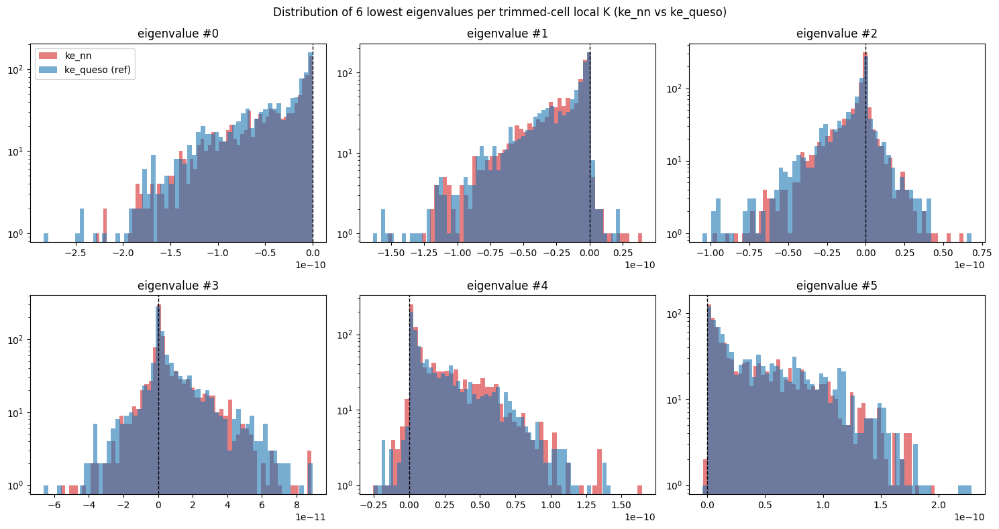


cells with at least one negative eigenvalue among lowest 6: 0 / 1016

mode 5 (last expected rigid-body mode) stats:  min/max = -3.5257213666190683e-12 1.9653531550327105e-10
mode 6 (first expected elastic mode) stats:    min/max = 0.00012716652073949838 64131.383586867385


In [88]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# ── symmetrize and get sorted eigenvalues per cell ──────────────────────────
ke_nn_sym = 0.5 * (ke_nn + ke_nn.transpose(-1, -2))
eigs_nn = torch.linalg.eigvalsh(ke_nn_sym)          # (T, ndof) ascending
eigs_nn_np = eigs_nn.detach().cpu().numpy()

n_modes = 6
lowest6 = eigs_nn_np[:, :n_modes]                    # (T, 6)

# same for the QuESo reference on the same trimmed cells, for comparison
ke_queso_trim_sym = 0.5 * (ke_queso_trim + ke_queso_trim.transpose(-1, -2))
eigs_queso = torch.linalg.eigvalsh(ke_queso_trim_sym).detach().cpu().numpy()
lowest6_queso = eigs_queso[:, :n_modes]

# ── print summary stats per mode ────────────────────────────────────────────
print(f"{'mode':>5} | {'min':>12} | {'max':>12} | {'mean':>12} | {'std':>12} | {'#neg':>6}")
for m in range(n_modes):
    col = lowest6[:, m]
    print(f"{m:>5} | {col.min():12.4e} | {col.max():12.4e} | {col.mean():12.4e} | "
          f"{col.std():12.4e} | {(col < -1e-8).sum():6d}")

# ── plot: one subplot per mode, ke_nn vs ke_queso overlaid ──────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for m, ax in enumerate(axes.flat):
    ax.hist(lowest6[:, m], bins=60, alpha=0.6, label='ke_nn', color='tab:red')
    ax.hist(lowest6_queso[:, m], bins=60, alpha=0.6, label='ke_queso (ref)', color='tab:blue')
    ax.axvline(0.0, color='k', linestyle='--', linewidth=1)
    ax.set_title(f'eigenvalue #{m}')
    ax.set_yscale('log')
    if m == 0:
        ax.legend()
plt.suptitle('Distribution of 6 lowest eigenvalues per trimmed-cell local K (ke_nn vs ke_queso)')
plt.tight_layout()
plt.show()

# ── flag: how many cells have ANY of the first 6 eigenvalues meaningfully negative ─
neg_any = (lowest6 < -1e-6).any(axis=1)
print(f"\ncells with at least one negative eigenvalue among lowest 6: {neg_any.sum()} / {lowest6.shape[0]}")

# for reference: rigid body modes should be ~0, not negative — check mode index 5 (last "should-be-zero" mode)
# vs mode index 6 (first genuinely elastic mode) to see if the separation is clean
print("\nmode 5 (last expected rigid-body mode) stats:  min/max =",
      lowest6[:, 5].min(), lowest6[:, 5].max())
print("mode 6 (first expected elastic mode) stats:    min/max =",
      eigs_nn_np[:, 6].min(), eigs_nn_np[:, 6].max())

In [89]:
ke_all_hybrid

tensor([[[ 7.8288e+01,  1.0048e+01, -1.4478e+01,  ...,  3.0435e+02,
           6.7459e+01, -2.0261e+01],
         [ 1.0048e+01,  2.2056e+01, -1.4830e+01,  ...,  1.0368e+02,
           6.5709e+01, -4.9828e+00],
         [-1.4478e+01, -1.4830e+01,  5.1172e+01,  ...,  8.9574e+01,
          -3.0737e+01,  5.3496e+01],
         ...,
         [ 3.0435e+02,  1.0368e+02,  8.9574e+01,  ...,  7.7065e+03,
          -3.2168e+02, -2.9390e+02],
         [ 6.7459e+01,  6.5709e+01, -3.0737e+01,  ..., -3.2168e+02,
           2.3903e+03,  6.6428e+01],
         [-2.0261e+01, -4.9828e+00,  5.3496e+01,  ..., -2.9390e+02,
           6.6428e+01,  2.2514e+03]],

        [[ 1.5765e+03,  1.6136e+02,  8.6570e+01,  ...,  2.0399e+03,
           2.1627e+02,  9.2597e+01],
         [ 1.6136e+02,  8.1740e+02, -2.5783e+01,  ...,  4.0985e+02,
           5.3055e+02, -9.1940e+01],
         [ 8.6570e+01, -2.5783e+01,  5.1236e+02,  ...,  8.2650e+01,
          -4.5066e+01,  5.1471e+02],
         ...,
         [ 2.0399e+03,  4

In [90]:
worst_cond = torch.argsort(cond_nn, descending=True)[:20]
print("cell ids with worst conditioning:", cell_ids[worst_cond])
print("min eigs there:", min_eig_nn[worst_cond])

neg_eig_mask = min_eig_nn < -1e-6
print("count with genuinely negative eigenvalues:", neg_eig_mask.sum().item())
print("their cell ids:", cell_ids[neg_eig_mask])

cell ids with worst conditioning: tensor([11956,  7603, 15043, 19393, 11953, 15046, 19396, 19303, 19306, 16788,
        12201,  7693, 17658, 12111, 14656, 14798, 12346, 10488, 10481, 14901])
min eigs there: tensor([-7.2399e-11, -1.1976e-10, -1.1604e-10, -1.1439e-10, -7.4424e-11,
        -5.8279e-11, -1.5283e-10, -1.7266e-10, -1.7321e-10, -1.8621e-10,
        -6.3231e-11, -1.8090e-10, -1.8779e-10, -6.1721e-11, -1.8581e-10,
        -1.3235e-10, -1.2923e-10, -1.7910e-10, -8.7232e-11, -9.5716e-11],
       dtype=torch.float64)
count with genuinely negative eigenvalues: 0
their cell ids: tensor([], dtype=torch.int64)


In [91]:
def compute_volume_fraction(case, cell_ids):
    grid = case.grid
    bounds_min = np.asarray(grid.bounds[0], dtype=np.float64)
    dxyz = np.array([grid.dx, grid.dy, grid.dz], dtype=np.float64)

    pts = np.asarray(case.ips)          # (P, 4): x,y,z,w  — adjust column order if needed
    xyz, w = pts[:, :3], pts[:, 3]

    ijk = np.floor((xyz - bounds_min[None, :]) / dxyz[None, :]).astype(np.int64)
    ny, nz = grid.resolution[1], grid.resolution[2]
    pt_cell_id = ijk[:, 0] * (ny * nz) + ijk[:, 1] * nz + ijk[:, 2]

    full_vol = float(grid.dx * grid.dy * grid.dz)
    cell_ids_np = np.asarray(cell_ids)

    frac = np.zeros(len(cell_ids_np), dtype=np.float64)
    for i, c in enumerate(cell_ids_np):
        frac[i] = w[pt_cell_id == c].sum() / full_vol
    return frac

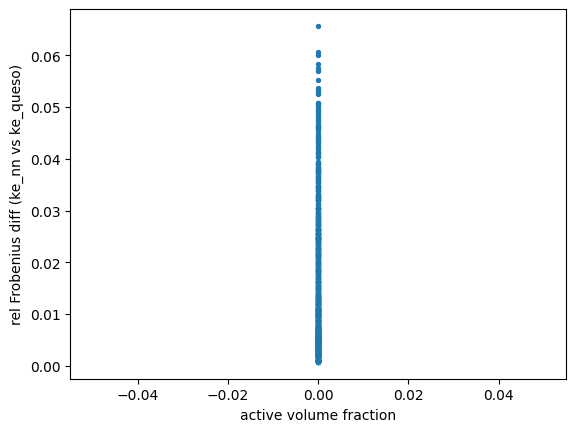

In [92]:
# compare against volume fraction, as planned earlier
vol_frac = compute_volume_fraction(case, queso_active)

# rel_diff already computed earlier
plt.scatter(vol_frac, rel_diff.numpy(), s=8)
plt.xlabel('active volume fraction'); plt.ylabel('rel Frobenius diff (ke_nn vs ke_queso)')
plt.show()

# also check: does the error correlate with cell position relative to training data bounds?
# e.g. if training data was generated on random trims, check if these specific
# cut orientations/fractions are underrepresented

In [93]:
# per-mode relative error across all trimmed cells, not just the lowest 6
eig_rel_err = (eigs_nn_np - eigs_queso) / np.abs(eigs_queso).clip(min=1e-8)

for m in [0, 5, 6, 10, 15, 17, 20, -1]:
    col = eig_rel_err[:, m]
    print(f"mode {m:>3}: median rel err={np.median(col):.3e}  "
          f"p90={np.percentile(np.abs(col),90):.3e}  max={np.abs(col).max():.3e}")

mode   0: median rel err=7.766e-05  p90=5.707e-03  max=1.819e-02
mode   5: median rel err=-1.399e-04  p90=5.590e-03  max=1.608e-02
mode   6: median rel err=-1.428e-03  p90=8.353e-01  max=6.105e+00
mode  10: median rel err=6.151e-04  p90=5.904e-01  max=2.708e+00
mode  15: median rel err=-6.873e-03  p90=1.142e-01  max=2.379e+00
mode  17: median rel err=-3.380e-03  p90=5.787e-02  max=1.626e+00
mode  20: median rel err=-3.358e-03  p90=2.618e-02  max=6.972e-02
mode  -1: median rel err=-3.166e-03  p90=2.547e-02  max=6.341e-02


In [94]:
for m in range(6):
    abs_err = np.abs(eigs_nn_np[:, m] - eigs_queso[:, m])
    print(f"mode {m}: abs err median={np.median(abs_err):.3e} max={abs_err.max():.3e}  "
          f"(ref queso scale ~{np.median(np.abs(eigs_queso[:,m])):.3e})")

mode 0: abs err median=1.082e-11 max=1.819e-10  (ref queso scale ~3.762e-11)
mode 1: abs err median=6.376e-12 max=1.376e-10  (ref queso scale ~1.456e-11)
mode 2: abs err median=5.714e-12 max=1.029e-10  (ref queso scale ~5.409e-12)
mode 3: abs err median=5.234e-12 max=1.065e-10  (ref queso scale ~4.967e-12)
mode 4: abs err median=6.570e-12 max=1.275e-10  (ref queso scale ~1.553e-11)
mode 5: abs err median=1.155e-11 max=1.608e-10  (ref queso scale ~3.818e-11)


In [12]:
print(gamma_v.min(), gamma_v.max(), gamma_v.mean(), gamma_v.std())
print(np.percentile(gamma_v, [0, 1, 5, 50, 95, 99, 100]))

tensor(1.0451e+08, dtype=torch.float64) tensor(1.3968e+08, dtype=torch.float64) tensor(1.2534e+08, dtype=torch.float64) tensor(8766613.9979, dtype=torch.float64)
[1.04507413e+08 1.04507413e+08 1.08374204e+08 1.27136198e+08
 1.38921317e+08 1.39675418e+08 1.39675418e+08]


In [96]:
# Magnitude of the QuESo displacement
u_mag = torch.linalg.norm(u_q_nodes, dim=1)

print(f"Min displacement : {u_mag.min():.6e}")
print(f"Mean displacement: {u_mag.mean():.6e}")
print(f"Max displacement : {u_mag.max():.6e}")

# Largest displacements
vals, idx = torch.topk(u_mag, 20)

print("\nTop 20 displacement magnitudes")
for i, (ii, vv) in enumerate(zip(idx.tolist(), vals.tolist()), 1):
    print(f"{i:2d}: node {ii:6d}   |u| = {vv:.6e}")

Min displacement : 0.000000e+00
Mean displacement: 5.864092e-04
Max displacement : 9.813164e-02

Top 20 displacement magnitudes
 1: node  17848   |u| = 9.813164e-02
 2: node  12082   |u| = 9.813164e-02
 3: node  17724   |u| = 9.812815e-02
 4: node  11958   |u| = 9.812815e-02
 5: node  13074   |u| = 7.469259e-02
 6: node  16918   |u| = 7.469259e-02
 7: node  12888   |u| = 7.469226e-02
 8: node  16732   |u| = 7.469226e-02
 9: node  12051   |u| = 1.941194e-02
10: node  17817   |u| = 1.941194e-02
11: node  11989   |u| = 1.941175e-02
12: node  17755   |u| = 1.941175e-02
13: node  18622   |u| = 1.823804e-02
14: node  10934   |u| = 1.823804e-02
15: node  18870   |u| = 1.823756e-02
16: node  11182   |u| = 1.823756e-02
17: node  13849   |u| = 1.340063e-02
18: node  15771   |u| = 1.340063e-02
19: node  15957   |u| = 1.340062e-02
20: node  14035   |u| = 1.340062e-02


In [97]:
err = torch.linalg.norm(u_q_nodes - u_h_nodes, dim=1)

vals, idx = torch.topk(err, 20)

print("\nTop 20 absolute errors")
for i, (ii, vv) in enumerate(zip(idx.tolist(), vals.tolist()), 1):
    print(f"{i:2d}: node {ii:6d}   err = {vv:.6e}   |u_q| = {u_mag[ii]:.6e}")


Top 20 absolute errors
 1: node  12082   err = 7.763862e-02   |u_q| = 9.813164e-02
 2: node  17724   err = 6.307490e-02   |u_q| = 9.812815e-02
 3: node  11958   err = 5.396821e-02   |u_q| = 9.812815e-02
 4: node  13074   err = 5.130653e-02   |u_q| = 7.469259e-02
 5: node  16732   err = 4.618385e-02   |u_q| = 7.469226e-02
 6: node  12888   err = 3.493730e-02   |u_q| = 7.469226e-02
 7: node  17848   err = 3.300819e-02   |u_q| = 9.813164e-02
 8: node  16918   err = 2.982403e-02   |u_q| = 7.469259e-02
 9: node  10934   err = 1.551960e-02   |u_q| = 1.823804e-02
10: node  18622   err = 1.253008e-02   |u_q| = 1.823804e-02
11: node  11182   err = 1.228331e-02   |u_q| = 1.823756e-02
12: node  18870   err = 1.165532e-02   |u_q| = 1.823756e-02
13: node  20760   err = 2.456090e-03   |u_q| = 6.842570e-03
14: node  19645   err = 2.048579e-03   |u_q| = 6.676639e-03
15: node  20574   err = 1.959992e-03   |u_q| = 6.842492e-03
16: node   9042   err = 1.906757e-03   |u_q| = 6.842492e-03
17: node  19769 

In [113]:
# --- Displacement errors (vectorized over nodes) -----------------------------

# u_q and u_h have shape (n_nodes, n_dim)

# QuESo displacement magnitude at each node
norm_uq = torch.linalg.norm(u_q_nodes, dim=1)

# Ignore fully constrained nodes
mask = norm_uq > 1e-6

# Maximum QuESo displacement magnitude (scalar)
max_norm_uq = torch.max(norm_uq[mask])

# Absolute displacement error per node
abs_l2 = torch.linalg.norm(u_q_nodes - u_h_nodes, dim=1)

# Relative displacement error per node
rel_l2 = torch.zeros_like(abs_l2)
rel_l2[mask] = abs_l2[mask] / norm_uq[mask]

# Normalized displacement error per node
normalized_displacement = torch.zeros_like(abs_l2)
normalized_displacement[mask] = abs_l2[mask] / max_norm_uq

print(f"\n── Displacement: Hybrid vs QuESo ──────")
print(f"Maximum QuESo displacement: {max_norm_uq:.4e} m")
print(f"Mean absolute error:        {abs_l2[mask].mean():.4e} m")
print(f"Mean relative error:        {100*rel_l2[mask].mean():.4f}%")
print(f"Mean normalized error:      {100*normalized_displacement[mask].mean():.4f}%")


── Displacement: Hybrid vs QuESo ──────
Maximum QuESo displacement: 9.8132e-02 m
Mean absolute error:        1.8783e-04 m
Mean relative error:        1.0560%
Mean normalized error:      0.1914%


NODAL DISPLACEMENT ERROR STATISTICS

Absolute error (m)
------------------
Nodes           : 2993
Mean            : 1.878281e-04
Median          : 1.674509e-05
Std             : 2.682540e-03
Min             : 2.861458e-06
Max             : 7.763862e-02
Q1              : 1.135693e-05
Q3              : 2.249195e-05
95th percentile : 1.144740e-04
99th percentile : 1.041712e-03

Relative error (-)
------------------
Nodes           : 2993
Mean            : 1.056027e-02
Median          : 3.003922e-03
Std             : 4.730127e-02
Min             : 5.069397e-04
Max             : 8.509468e-01
Q1              : 2.088773e-03
Q3              : 3.971364e-03
95th percentile : 3.179834e-02
99th percentile : 1.932757e-01

Normalized error (-)
--------------------
Nodes           : 2993
Mean            : 1.914042e-03
Median          : 1.706390e-04
Std             : 2.733613e-02
Min             : 2.915938e-05
Max             : 7.911681e-01
Q1              : 1.157316e-04
Q3              : 2.292018e-04

C:\Users\z0058p1u\AppData\Local\Temp\ipykernel_33856\2636275686.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(



TOP 10 LARGEST ERRORS

Absolute error (m)
 1: node=   823   error=7.763862e-02
 2: node=  2185   error=6.307490e-02
 3: node=   755   error=5.396821e-02
 4: node=  1073   error=5.130653e-02
 5: node=  1935   error=4.618385e-02
 6: node=   971   error=3.493730e-02
 7: node=  2253   error=3.300819e-02
 8: node=  2037   error=2.982403e-02
 9: node=   515   error=1.551960e-02
10: node=  2371   error=1.253008e-02

Relative error (-)
 1: node=   515   error=8.509468e-01
 2: node=   823   error=7.911681e-01
 3: node=  2371   error=6.870301e-01
 4: node=  1073   error=6.869025e-01
 5: node=   635   error=6.735169e-01
 6: node=  2185   error=6.427809e-01
 7: node=  2491   error=6.390836e-01
 8: node=  1935   error=6.183217e-01
 9: node=   755   error=5.499769e-01
10: node=   971   error=4.677499e-01

Normalized error (-)
 1: node=   823   error=7.911681e-01
 2: node=  2185   error=6.427581e-01
 3: node=   755   error=5.499573e-01
 4: node=  1073   error=5.228337e-01
 5: node=  1935   error=4.7

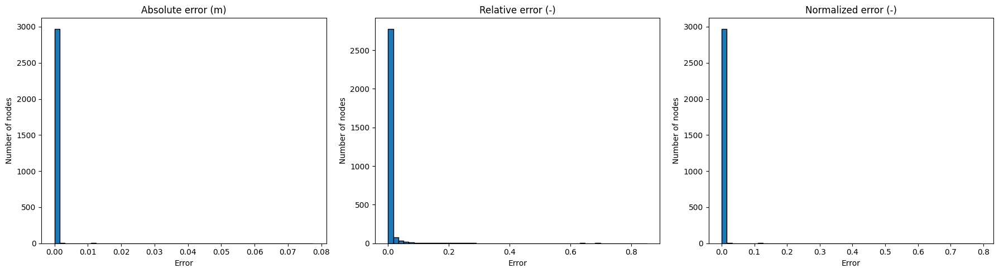

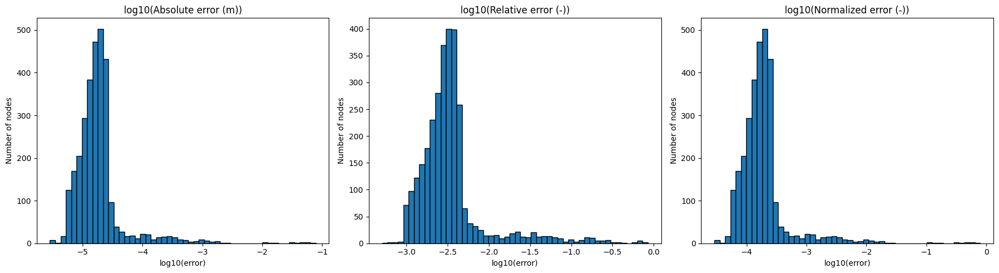

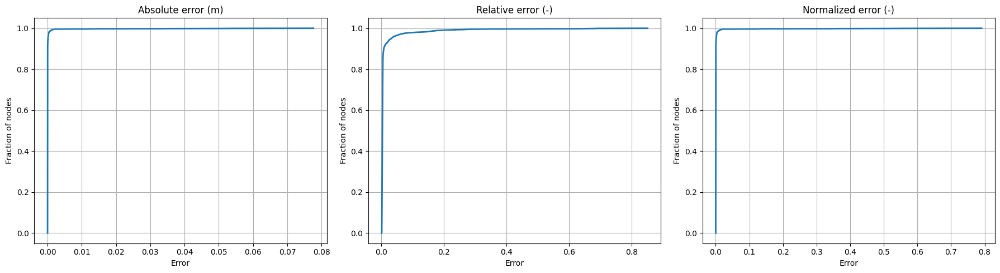

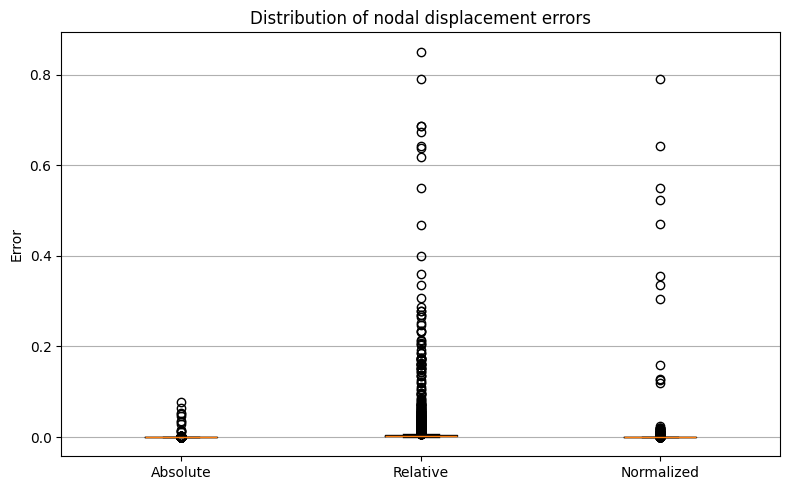

In [99]:
# =============================================================================
# Distribution study of nodal displacement errors
# =============================================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# Select the error to analyze
# -------------------------------------------------------------------------
errors = {
    "Absolute error (m)"      : abs_l2,
    "Relative error (-)"      : rel_l2,
    "Normalized error (-)"    : normalized_displacement,
}

# -------------------------------------------------------------------------
# Statistics
# -------------------------------------------------------------------------
print("="*80)
print("NODAL DISPLACEMENT ERROR STATISTICS")
print("="*80)

for name, err in errors.items():

    e = err[mask]

    print(f"\n{name}")
    print("-"*len(name))
    print(f"Nodes           : {len(e)}")
    print(f"Mean            : {e.mean():.6e}")
    print(f"Median          : {e.median():.6e}")
    print(f"Std             : {e.std():.6e}")
    print(f"Min             : {e.min():.6e}")
    print(f"Max             : {e.max():.6e}")
    print(f"Q1              : {torch.quantile(e,0.25):.6e}")
    print(f"Q3              : {torch.quantile(e,0.75):.6e}")
    print(f"95th percentile : {torch.quantile(e,0.95):.6e}")
    print(f"99th percentile : {torch.quantile(e,0.99):.6e}")

# -------------------------------------------------------------------------
# Histograms
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18,5))

for ax, (name, err) in zip(axes, errors.items()):

    e = err[mask].cpu().numpy()

    ax.hist(e, bins=50, edgecolor="black")
    ax.set_title(name)
    ax.set_xlabel("Error")
    ax.set_ylabel("Number of nodes")

plt.tight_layout()

# -------------------------------------------------------------------------
# Log-histograms (ignore zeros)
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18,5))

for ax, (name, err) in zip(axes, errors.items()):

    e = err[mask]
    e = e[e > 0].cpu().numpy()

    ax.hist(np.log10(e), bins=50, edgecolor="black")
    ax.set_title(f"log10({name})")
    ax.set_xlabel("log10(error)")
    ax.set_ylabel("Number of nodes")

plt.tight_layout()

# -------------------------------------------------------------------------
# Empirical cumulative distribution function (ECDF)
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18,5))

for ax, (name, err) in zip(axes, errors.items()):

    e = torch.sort(err[mask]).values.cpu().numpy()
    F = np.arange(1, len(e)+1)/len(e)

    ax.plot(e, F, lw=2)
    ax.set_title(name)
    ax.set_xlabel("Error")
    ax.set_ylabel("Fraction of nodes")
    ax.grid(True)

plt.tight_layout()

# -------------------------------------------------------------------------
# Boxplots
# -------------------------------------------------------------------------
plt.figure(figsize=(8,5))

plt.boxplot(
    [abs_l2[mask].cpu().numpy(),
     rel_l2[mask].cpu().numpy(),
     normalized_displacement[mask].cpu().numpy()],
    labels=["Absolute","Relative","Normalized"],
    showfliers=True
)

plt.ylabel("Error")
plt.title("Distribution of nodal displacement errors")
plt.grid(axis='y')

plt.tight_layout()

# -------------------------------------------------------------------------
# Worst nodes
# -------------------------------------------------------------------------
k = 10

print("\n" + "="*80)
print(f"TOP {k} LARGEST ERRORS")
print("="*80)

for name, err in errors.items():

    vals, idx = torch.topk(err[mask], k)

    print(f"\n{name}")
    for i, (ii, ee) in enumerate(zip(idx.tolist(), vals.tolist()), 1):
        print(f"{i:2d}: node={ii:6d}   error={ee:.6e}")

In [100]:
#compute coords with dx, dy, dz and bounds = [[-15, -15, -15], [15, 15, 15]]
xmin, ymin, zmin = case.grid.bounds[0]
xmax, ymax, zmax = case.grid.bounds[1]

x = np.arange(xmin, xmax + 0.5*case.grid.dx, case.grid.dx)
y = np.arange(ymin, ymax + 0.5*case.grid.dy, case.grid.dy)
z = np.arange(zmin, zmax + 0.5*case.grid.dz, case.grid.dz)

X, Y, Z = np.meshgrid(x, y, z, indexing="ij")

coords = np.column_stack((X.ravel(), Y.ravel(), Z.ravel()))

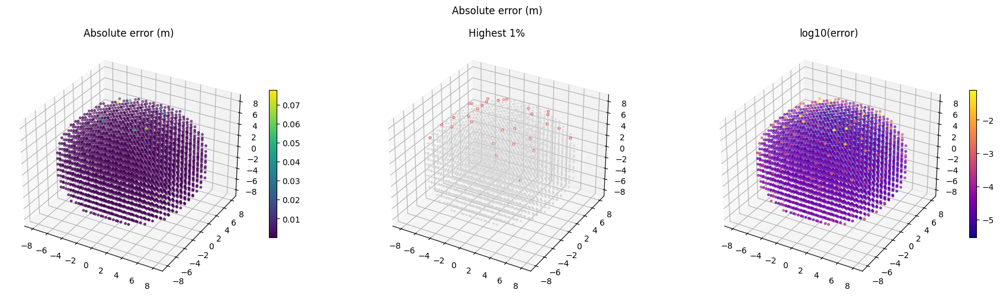

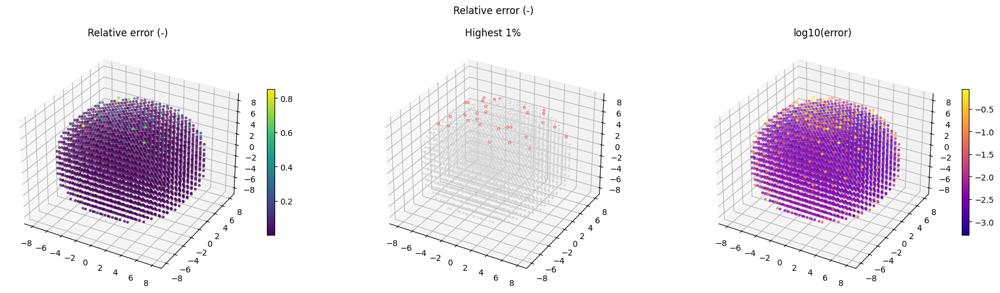

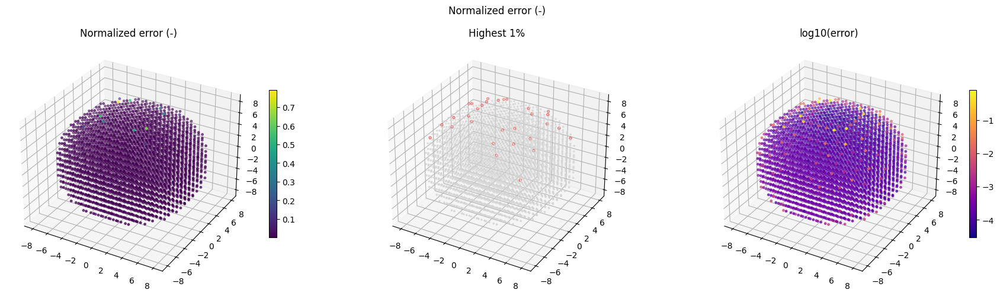

In [101]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================================
# Spatial distribution of nodal displacement errors
# ============================================================================

metrics = {
    "Absolute error (m)"   : abs_l2,
    "Relative error (-)"   : rel_l2,
    "Normalized error (-)" : normalized_displacement,
}

coords_np = coords.cpu().numpy() if torch.is_tensor(coords) else np.asarray(coords)
dim = coords_np.shape[1]

mask_np = mask.cpu().numpy()

for title, error in metrics.items():

    err = error.cpu().numpy() if torch.is_tensor(error) else np.asarray(error)

    # Active nodes
    xyz = coords_np[mask_np]
    e = err[mask_np]

    # Highest 1%
    threshold = np.quantile(e, 0.99)
    hot = e >= threshold

    if dim == 2:

        fig, ax = plt.subplots(1, 3, figsize=(18,5))

        # ---------------------------------------------------------------
        # Continuous error field
        # ---------------------------------------------------------------
        im = ax[0].scatter(
            xyz[:,0], xyz[:,1],
            c=e,
            s=10,
            cmap="viridis"
        )

        plt.colorbar(im, ax=ax[0])
        ax[0].set_title(title)
        ax[0].set_aspect("equal")

        # ---------------------------------------------------------------
        # Highest 1%
        # ---------------------------------------------------------------
        ax[1].scatter(
            xyz[:,0], xyz[:,1],
            c="lightgray",
            s=4
        )

        ax[1].scatter(
            xyz[hot,0],
            xyz[hot,1],
            c="red",
            s=12
        )

        ax[1].set_title("Highest 1%")
        ax[1].set_aspect("equal")

        # ---------------------------------------------------------------
        # Smooth contour map
        # ---------------------------------------------------------------
        tcf = ax[2].tricontourf(
            xyz[:,0],
            xyz[:,1],
            e,
            levels=30,
            cmap="viridis"
        )

        plt.colorbar(tcf, ax=ax[2])
        ax[2].set_title("Interpolated field")
        ax[2].set_aspect("equal")

        plt.suptitle(title)
        plt.tight_layout()

    else:

        fig = plt.figure(figsize=(18,5))

        # ---------------------------------------------------------------
        # Colored point cloud
        # ---------------------------------------------------------------
        ax = fig.add_subplot(131, projection="3d")

        sc = ax.scatter(
            xyz[:,0],
            xyz[:,1],
            xyz[:,2],
            c=e,
            s=6,
            cmap="viridis"
        )

        plt.colorbar(sc, ax=ax, shrink=.6)
        ax.set_title(title)

        # ---------------------------------------------------------------
        # Highest 1%
        # ---------------------------------------------------------------
        ax = fig.add_subplot(132, projection="3d")

        ax.scatter(
            xyz[:,0],
            xyz[:,1],
            xyz[:,2],
            c="lightgray",
            s=3
        )

        ax.scatter(
            xyz[hot,0],
            xyz[hot,1],
            xyz[hot,2],
            c="red",
            s=8
            
        )

        ax.set_title("Highest 1%")

        # ---------------------------------------------------------------
        # Log-error visualization
        # ---------------------------------------------------------------
        ax = fig.add_subplot(133, projection="3d")

        sc = ax.scatter(
            xyz[:,0],
            xyz[:,1],
            xyz[:,2],
            c=np.log10(np.maximum(e,1e-16)),
            s=6,
            cmap="plasma"
        )

        plt.colorbar(sc, ax=ax, shrink=.6)
        ax.set_title("log10(error)")

        plt.suptitle(title)
        plt.tight_layout()

In [67]:
coords = case.grid.node_coordinates()

err = torch.linalg.norm(u_q_nodes - u_h_nodes, dim=1)

vals, idx = torch.topk(err, 20)

print(f"{'z':>8} {'|u|':>12} {'err':>12}")
for i in idx:
    print(
        f"{coords[i,2]:8.2f} "
        f"{torch.linalg.norm(u_q_nodes[i]):12.4e} "
        f"{err[i]:12.4e}"
    )

       z          |u|          err
    8.00   9.8132e-02   7.7660e-02
    8.00   9.8128e-02   6.3122e-02
    8.00   9.8128e-02   5.4017e-02
    8.00   7.4693e-02   5.1337e-02
    8.00   7.4692e-02   4.6197e-02
    8.00   7.4692e-02   3.4956e-02
    8.00   9.8132e-02   3.3172e-02
    8.00   7.4693e-02   2.9893e-02
    7.00   1.8238e-02   1.5525e-02
    7.00   1.8238e-02   1.2554e-02
    7.00   1.8238e-02   1.2301e-02
    7.00   1.8238e-02   1.1710e-02
    6.00   6.8426e-03   2.3781e-03
    7.00   6.6766e-03   2.0512e-03
    6.00   6.8425e-03   1.9744e-03
    6.00   6.8425e-03   1.9245e-03
    7.00   6.6765e-03   1.8607e-03
    7.00   6.6765e-03   1.7975e-03
    7.00   6.6766e-03   1.6485e-03
    6.00   6.7670e-03   1.6213e-03


In [107]:
sorted(rel_l2)[::-1]

[tensor(0.8509, dtype=torch.float64),
 tensor(0.7912, dtype=torch.float64),
 tensor(0.6870, dtype=torch.float64),
 tensor(0.6869, dtype=torch.float64),
 tensor(0.6735, dtype=torch.float64),
 tensor(0.6428, dtype=torch.float64),
 tensor(0.6391, dtype=torch.float64),
 tensor(0.6183, dtype=torch.float64),
 tensor(0.5500, dtype=torch.float64),
 tensor(0.4677, dtype=torch.float64),
 tensor(0.3993, dtype=torch.float64),
 tensor(0.3589, dtype=torch.float64),
 tensor(0.3364, dtype=torch.float64),
 tensor(0.3068, dtype=torch.float64),
 tensor(0.2864, dtype=torch.float64),
 tensor(0.2792, dtype=torch.float64),
 tensor(0.2787, dtype=torch.float64),
 tensor(0.2691, dtype=torch.float64),
 tensor(0.2685, dtype=torch.float64),
 tensor(0.2659, dtype=torch.float64),
 tensor(0.2525, dtype=torch.float64),
 tensor(0.2467, dtype=torch.float64),
 tensor(0.2344, dtype=torch.float64),
 tensor(0.2344, dtype=torch.float64),
 tensor(0.2317, dtype=torch.float64),
 tensor(0.2152, dtype=torch.float64),
 tensor(0.21

In [102]:
coords = case.grid.node_coordinates()
u_mag = torch.linalg.norm(u_q_nodes, dim=1)

imax = torch.argmax(u_mag)

print("Maximum displacement")
print("coord =", coords[imax])
print("|u|   =", u_mag[imax])

Maximum displacement
coord = tensor([3., 2., 8.], dtype=torch.float64)
|u|   = tensor(0.0981, dtype=torch.float64)


In [22]:
print(type(nitsche_sets[0]))

if isinstance(nitsche_sets[0], dict):
    print(nitsche_sets[0].keys())

<class 'dict'>
dict_keys(['k_add', 'f_add', 'boundary_elems', 'gamma_v'])


In [23]:
nitsche_sets

[{'k_add': tensor(indices=tensor([[35871, 35871, 35871,  ..., 53546, 53546, 53546],
                         [35871, 35872, 35873,  ..., 53544, 53545, 53546]]),
         values=tensor([89.1837, -4.3468, 10.5270,  ..., -0.2523, -0.2139,
                         1.6378]),
         size=(89373, 89373), nnz=11700, dtype=torch.float64,
         layout=torch.sparse_coo),
  'f_add': tensor([0., 0., 0.,  ..., 0., 0., 0.], dtype=torch.float64),
  'boundary_elems': array([11212, 11242, 11272, 11302, 12082, 12112, 12142, 12172, 12202,
         12232, 12982, 13012, 13042, 13072, 13102, 13132, 13882, 13912,
         13942, 13972, 14002, 14032, 14782, 14812, 14842, 14872, 14902,
         14932, 15712, 15742, 15772, 15802]),
  'gamma_v': tensor([1.2829e+08, 1.2829e+08, 1.2829e+08, 1.2351e+08, 1.2351e+08, 1.2351e+08,
          1.2772e+08, 1.2772e+08, 1.2772e+08, 1.1817e+08, 1.1817e+08, 1.1817e+08,
          1.2317e+08, 1.2317e+08, 1.2317e+08, 1.3126e+08, 1.3126e+08, 1.3126e+08,
          1.3412e+08, 1

In [24]:
u_mag = torch.linalg.norm(u_q_nodes, dim=1)
coords = case.grid.node_coordinates()

# Nodes with essentially zero displacement
fixed = u_mag < 1e-8

print(f"Number of nearly fixed nodes: {fixed.sum()}")

print("z-range of nearly fixed nodes:")
print(coords[fixed][:,2].min(), coords[fixed][:,2].max())

print("x-range:")
print(coords[fixed][:,0].min(), coords[fixed][:,0].max())

print("y-range:")
print(coords[fixed][:,1].min(), coords[fixed][:,1].max())

Number of nearly fixed nodes: 26798
z-range of nearly fixed nodes:
tensor(-15., dtype=torch.float64) tensor(15., dtype=torch.float64)
x-range:
tensor(-15., dtype=torch.float64) tensor(15., dtype=torch.float64)
y-range:
tensor(-15., dtype=torch.float64) tensor(15., dtype=torch.float64)


In [253]:
coords = case.grid.node_coordinates()

print(coords.shape)
print(u_q_nodes.shape)

torch.Size([29791, 3])
torch.Size([29791, 3])


In [254]:
for i in [0, 1, 10, 100, 1000, torch.argmax(u_mag).item()]:
    print(i, coords[i], u_mag[i])

0 tensor([-15., -15., -15.], dtype=torch.float64) tensor(0., dtype=torch.float64)
1 tensor([-15., -15., -14.], dtype=torch.float64) tensor(0., dtype=torch.float64)
10 tensor([-15., -15.,  -5.], dtype=torch.float64) tensor(0., dtype=torch.float64)
100 tensor([-15., -12.,  -8.], dtype=torch.float64) tensor(0., dtype=torch.float64)
1000 tensor([-14., -14.,  -7.], dtype=torch.float64) tensor(0., dtype=torch.float64)
17848 tensor([3., 2., 8.], dtype=torch.float64) tensor(0.0981, dtype=torch.float64)


In [255]:
print(case.grid.node_coordinates().shape)
print(u_q_nodes.shape)

torch.Size([29791, 3])
torch.Size([29791, 3])


In [25]:
active = u_mag > 1e-10
coords = case.grid.node_coordinates()

print("z-range of active nodes:")
print(coords[active][:,2].min(), coords[active][:,2].max())

vals, idx = torch.topk(u_mag[active], 20, largest=False)

active_idx = torch.where(active)[0]

print("Smallest nonzero displacements")
for v, i in zip(vals, idx):
    g = active_idx[i]
    print(coords[g], v)

z-range of active nodes:
tensor(-8., dtype=torch.float64) tensor(8., dtype=torch.float64)
Smallest nonzero displacements
tensor([-2., -1.,  7.], dtype=torch.float64) tensor(5.4645e-05, dtype=torch.float64)
tensor([ 2., -1.,  7.], dtype=torch.float64) tensor(5.4645e-05, dtype=torch.float64)
tensor([-2.,  1.,  7.], dtype=torch.float64) tensor(5.4696e-05, dtype=torch.float64)
tensor([2., 1., 7.], dtype=torch.float64) tensor(5.4696e-05, dtype=torch.float64)
tensor([-1., -2.,  7.], dtype=torch.float64) tensor(6.5006e-05, dtype=torch.float64)
tensor([ 1., -2.,  7.], dtype=torch.float64) tensor(6.5006e-05, dtype=torch.float64)
tensor([-1.,  2.,  7.], dtype=torch.float64) tensor(6.5011e-05, dtype=torch.float64)
tensor([1., 2., 7.], dtype=torch.float64) tensor(6.5011e-05, dtype=torch.float64)
tensor([0., 2., 7.], dtype=torch.float64) tensor(0.0001, dtype=torch.float64)
tensor([ 0., -2.,  7.], dtype=torch.float64) tensor(0.0001, dtype=torch.float64)
tensor([-2.,  0.,  7.], dtype=torch.float64) t

In [ ]:
u_nodes = u_q_nodes

In [250]:
imax = torch.argmax(u_mag)
print(coords[imax])


tensor([3., 2., 8.], dtype=torch.float64)


In [150]:
import scipy.sparse as sp
import numpy.linalg as nla
from internal_fem_kernel.core.grid_indexing import active_element_nodes as _aen

def sparse_to_scipy(t: torch.Tensor) -> sp.csr_matrix:
    t = t.coalesce().cpu()
    idx, val, n = t.indices().numpy(), t.values().double().numpy(), t.shape[0]
    return sp.csr_matrix((val, (idx[0], idx[1])), shape=(n, n))

Kqf = sparse_to_scipy(K_q_full)
Khf = sparse_to_scipy(K_h_full)

f_np = F.double().cpu().numpy()
uq   = u_q.numpy()
uh   = u_h.numpy()

# ── Active-node mask (exclude the ~87 k inactive nodes outside the sphere) ──
active_node_idx = _aen(active_all, case.grid.resolution,
                        poly_order=case.poly_order, device='cpu').reshape(-1).unique().numpy()
# Each node has 3 DOFs; build DOF index from node index
active_dof_idx = np.concatenate([active_node_idx * 3,
                                  active_node_idx * 3 + 1,
                                  active_node_idx * 3 + 2])
active_dof_idx = np.sort(active_dof_idx)

uq_act = uq[active_dof_idx]
uh_act = uh[active_dof_idx]
f_act  = f_np[active_dof_idx]

# ── K norms ──────────────────────────────────────────────────────────────────
frob_Kq_n    = float(sp.linalg.norm(Kqf, 'fro'))
frob_dK_full = float(sp.linalg.norm(Kqf - Khf, 'fro'))

# ── Solver residuals (over active DOFs only) ──────────────────────────────────
res_q = float(nla.norm(Kqf @ uq - f_np) / (nla.norm(f_np) + 1e-30))
res_h = float(nla.norm(Khf @ uh - f_np) / (nla.norm(f_np) + 1e-30))

# ── Local Ke ─────────────────────────────────────────────────────────────────
ke_q_trim    = ke_all_queso[trimmed_positions]
abs_ke_err   = (ke_q_trim - ke_nn).norm(dim=(-2, -1))
rel_ke_err   = abs_ke_err / ke_q_trim.norm(dim=(-2, -1))
per_cell_rel = rel_ke_err

print('── Local Ke  (1016 trimmed cells) ───────────────────────')
print(f'  {"":22s}  {"absolute":>12s}  {"relative":>12s}')
print(f'  {"mean Frobenius error":22s}  {abs_ke_err.mean():>12.4f}  {rel_ke_err.mean():>12.4f}')
print(f'  {"median":22s}  {abs_ke_err.median():>12.4f}  {rel_ke_err.median():>12.4f}')
print(f'  {"p95":22s}  {torch.quantile(abs_ke_err,0.95):>12.4f}  {torch.quantile(rel_ke_err,0.95):>12.4f}')
print(f'  {"max":22s}  {abs_ke_err.max():>12.4f}  {rel_ke_err.max():>12.4f}')

print('\n── Global K  (with Nitsche) ──────────────────────────────')
print(f'  {"":22s}  {"absolute (Frob)":>15s}  {"relative":>12s}')
print(f'  {"||K||":22s}  {frob_Kq_n:>15.4e}  {"—":>12s}')
print(f'  {"||ΔK||":22s}  {frob_dK_full:>15.4e}  {frob_dK_full/frob_Kq_n:>12.4e}')

print('\n── Solver residuals  ||(K+N)u - F|| / ||F|| ────────────')
print(f'  QuESo  : {res_q:.2e}  (converged ✓)' if res_q < 1e-5 else f'  QuESo  : {res_q:.2e}')
print(f'  Hybrid : {res_h:.2e}  (converged ✓)' if res_h < 1e-5 else f'  Hybrid : {res_h:.2e}')

# ── Displacement — active nodes only ─────────────────────────────────────────
n_active_nodes = len(active_node_idx)
uq_act_nodes = uq_act.reshape(-1, 3)        # (n_active, 3)
uh_act_nodes = uh_act.reshape(-1, 3)
du_act_nodes = uq_act_nodes - uh_act_nodes

abs_u_err = nla.norm(du_act_nodes, axis=1)                           # (n_active,) absolute
u_q_mag = np.linalg.norm(u_q_nodes, axis=1, ord=2)

# global maximum displacement magnitude
ref_u = u_q_mag.max()               # (n_active,) reference
rel_u_err  = abs_u_err / ref_u                                       # (n_active,) relative

norm_uq_act = float(nla.norm(uq_act))
norm_du_act = float(nla.norm(uq_act - uh_act))

print(f'\n── Displacement  (active nodes only: {n_active_nodes}) ─────────────')
print(f'  {"":22s}  {"absolute":>15s}  {"relative":>12s}')
print(f'  {"||u||_2":22s}  {norm_uq_act:>15.4e}  {"—":>12s}')
print(f'  {"||Δu||_2 (global L2)":22s}  {norm_du_act:>15.4e}  {norm_du_act/norm_uq_act:>12.4e}')
print(f'  {"max  node ||Δu||":22s}  {abs_u_err.max():>15.4e}  {rel_u_err.max():>12.4e}')
print(f'  {"mean node ||Δu||":22s}  {abs_u_err.mean():>15.4e}  {rel_u_err.mean():>12.4e}')
print(f'  {"median node ||Δu||":22s}  {float(np.median(abs_u_err)):>15.4e}  {float(np.median(rel_u_err)):>12.4e}')

# ── Amplification ─────────────────────────────────────────────────────────────
dk_rel = frob_dK_full / frob_Kq_n
du_rel = norm_du_act / norm_uq_act
print('\n── Amplification ────────────────────────────────────────')
print(f'  ||ΔK+N|| / ||K+N||         : {dk_rel:.4e}')
print(f'  ||Δu||   / ||u||           : {du_rel:.4e}')
print(f'  amplification ≈ κ          : {du_rel/max(dk_rel,1e-30):.1f}×')
print(f'  ⟹ to reach <1% Δu/u,  need local ΔKe/Ke < {0.01/max(du_rel/max(dk_rel,1e-30),1):.2e}')

── Local Ke  (1016 trimmed cells) ───────────────────────
                              absolute      relative
  mean Frobenius error       8069.3684        0.0197
  median                     6726.7669        0.0117
  p95                       18027.7707        0.0592
  max                       28958.1874        0.1090

── Global K  (with Nitsche) ──────────────────────────────
                          absolute (Frob)      relative
  ||K||                        3.2567e+08             —
  ||ΔK||                       4.3266e+05    1.3285e-03

── Solver residuals  ||(K+N)u - F|| / ||F|| ────────────
  QuESo  : 9.89e-08  (converged ✓)
  Hybrid : 8.59e-08  (converged ✓)

── Displacement  (active nodes only: 2993) ─────────────
                                 absolute      relative
  ||u||_2                      4.0010e-01             —
  ||Δu||_2 (global L2)         1.6152e-01    4.0370e-01
  max  node ||Δu||             8.2608e-02    8.4181e-01
  mean node ||Δu||             2.4395e-

In [11]:
import numpy as np

coords = case.grid.node_coordinates(poly_order=case.poly_order).cpu().numpy()

uq = u_q.cpu().numpy().reshape(-1,3)
uh = u_h.cpu().numpy().reshape(-1,3)

coords_act = coords[active_node_idx]

uq_act = uq[active_node_idx]
uh_act = uh[active_node_idx]

scale = 500      # exaggerate deformation

X_ref = coords_act
X_q   = coords_act + scale * uq_act
X_h   = coords_act + scale * uh_act

In [ ]:
du = uh_act - uq_act

X_err = coords_act + scale * du

err = np.linalg.norm(du, axis=1, ord=2)

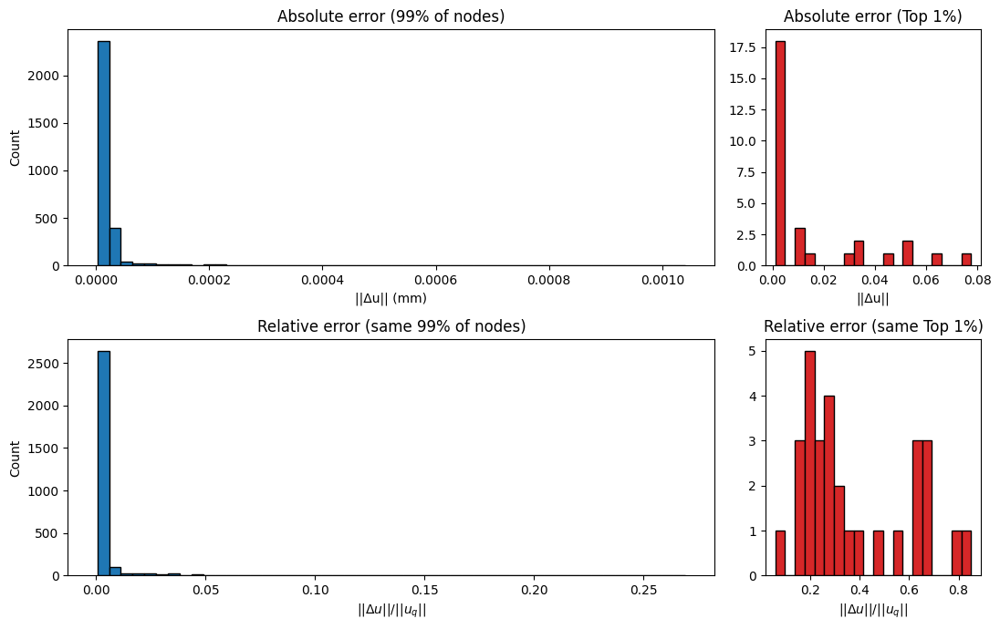

Absolute error (mm)
99% threshold : 0.001042
Outliers      : 30 / 2993

Relative error
Mean   : 1.0560%
Median : 0.3004%
95%    : 3.1798%
99%    : 19.3276%
Max    : 85.0947%


In [115]:
import matplotlib.pyplot as plt
import numpy as np



# global maximum displacement magnitude
u_q_max = u_q_mag.max()
# Relative error
rel_err = rel_l2[mask]

# Threshold defining the outliers (same for both rows)
threshold = np.percentile(abs_l2[mask], 99)

bulk = abs_l2[mask] <= threshold
tail = ~bulk

fig, axs = plt.subplots(
    2, 2,
    figsize=(11, 7),
    gridspec_kw={"width_ratios": [3, 1]}
)

# ==========================================================
# Top row : absolute error
# ==========================================================

axs[0,0].hist(abs_l2[mask][bulk], bins=50, edgecolor="black")
axs[0,0].set_title("Absolute error (99% of nodes)")
axs[0,0].set_xlabel("||Δu|| (mm)")
axs[0,0].set_ylabel("Count")

axs[0,1].hist(abs_l2[mask][tail], bins=20, color="tab:red", edgecolor="black")
axs[0,1].set_title("Absolute error (Top 1%)")
axs[0,1].set_xlabel("||Δu||")

# ==========================================================
# Bottom row : relative error (same nodes)
# ==========================================================

axs[1,0].hist(rel_err[bulk], bins=50, edgecolor="black")
axs[1,0].set_title("Relative error (same 99% of nodes)")
axs[1,0].set_xlabel(r"$||\Delta u|| / ||u_q||$")
axs[1,0].set_ylabel("Count")

axs[1,1].hist(rel_err[tail], bins=20, color="tab:red", edgecolor="black")
axs[1,1].set_title("Relative error (same Top 1%)")
axs[1,1].set_xlabel(r"$||\Delta u|| / ||u_q||$")

plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# Statistics
# ----------------------------------------------------------

print("Absolute error (mm)")
print(f"99% threshold : {threshold:.6f}")
print(f"Outliers      : {tail.sum()} / {len(abs_l2[mask])}")

print()

print("Relative error")
print(f"Mean   : {rel_err.mean():.4%}")
print(f"Median : {np.median(rel_err):.4%}")
print(f"95%    : {np.percentile(rel_err,95):.4%}")
print(f"99%    : {np.percentile(rel_err,99):.4%}")
print(f"Max    : {rel_err.max():.4%}")

In [118]:
# did ke_all_hybrid get rebuilt from the corrected ke_nn_list?
ke_nn_fixed_stacked = torch.stack(ke_nn_list, dim=0)   # your corrected version
ke_all_hybrid_v2 = ke_all_queso.clone()
ke_all_hybrid_v2[trimmed_positions] = ke_nn_fixed_stacked

# sanity: did anything actually change vs the old hybrid?
print("max abs diff old vs new hybrid at trimmed cells:",
      (ke_all_hybrid_v2[trimmed_positions] - ke_all_hybrid[trimmed_positions]).abs().max().item())

max abs diff old vs new hybrid at trimmed cells: 0.0


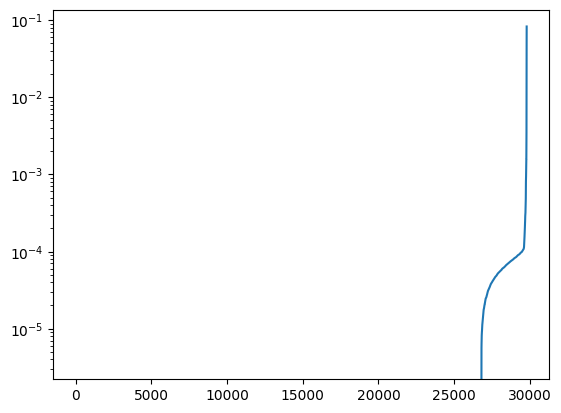

In [26]:
err = np.linalg.norm(
    uq.reshape(-1,3)-uh.reshape(-1,3),
    axis=1,
    ord=2,
)

plt.semilogy(np.sort(err))

In [197]:
err[np.linalg.norm(u_h_nodes, axis=1) > 0]

IndexError: boolean index did not match indexed array along axis 0; size of axis is 2993 but size of corresponding boolean axis is 29791

In [194]:
np.argsort(err[err > 1e-6])[0:]

array([ 821, 1279,  415, ..., 2185, 2253,  823], shape=(2993,))

In [27]:
u_q_nodes = uq.reshape(-1,3)
u_h_nodes = uh.reshape(-1,3)
  
err = np.linalg.norm(u_q_nodes-u_h_nodes,axis=1, ord=2)

idx = np.argsort(err)[-30:]

print(idx)
print(err[idx])

[ 8048 13135 12051  7302 17786 11989 17598  9228 16669  9042 20574 12204
 21750 17970 19769 20760 19645 10159 11182 18622 18870 10934 12888 13074
 16918 16732 11958 17724 17848 12082]
[0.00129627 0.00129741 0.00133232 0.00133857 0.00150126 0.00153636
 0.00156703 0.0015675  0.00164616 0.00169838 0.00173342 0.00178915
 0.00180488 0.0019566  0.00241754 0.00283729 0.00293279 0.00352504
 0.01206341 0.0122485  0.01297784 0.01464476 0.02985356 0.03184411
 0.04144675 0.04327205 0.05019384 0.06733384 0.07696765 0.08260797]


In [191]:
u_q_nodes[821]

array([0., 0., 0.])

In [189]:
u_h_nodes[12082]

array([ 0.02189003,  0.01384381, -0.0276037 ])

In [28]:
# R = build_rigid_body_modes(HEX_CORNER_COORDS).to(ke_queso[0].dtype)

In [29]:
# torch.norm(ke_queso[0] @ R)

In [30]:
u_q_nodes.shape

(29791, 3)

In [149]:
# displacement magnitude at each node
u_q_mag = np.linalg.norm(u_q_nodes, axis=1)

# global maximum displacement magnitude
u_q_max = u_q_mag.max()

# relative error
rel = err / (u_q_max + 1e-30)

i = np.argmax(rel)

print(i)
print(u_q_nodes[i])
print(u_h_nodes[i])
print(rel[i])

823
[0. 0. 0.]
[0. 0. 0.]
0.8418077422361286


In [32]:
import numpy as np

# --- reshape displacement vectors ---
uq_nodes = uq.reshape(-1, 3)
uh_nodes = uh.reshape(-1, 3)

# --- absolute error per node ---
err = np.linalg.norm(uq_nodes - uh_nodes, axis=1, ord=2)

# --- node coordinates ---
import numpy as np

nx, ny, nz = case.grid.resolution
p = case.poly_order

sx = nx * p + 1
sy = ny * p + 1
sz = nz * p + 1

# Use your actual grid spacing if available
dx = (case.grid.bounds[1][0] - case.grid.bounds[0][0]) / nx
dy = (case.grid.bounds[1][1] - case.grid.bounds[0][1]) / ny
dz = (case.grid.bounds[1][2] - case.grid.bounds[0][2]) / nz

xs = (np.arange(sx) + case.grid.bounds[0][0]) * dx
ys = (np.arange(sy) + case.grid.bounds[0][1]) * dy
zs = (np.arange(sz) + case.grid.bounds[0][2]) * dz

X, Y, Z = np.meshgrid(xs, ys, zs, indexing="ij")
coords = np.column_stack([X.ravel(), Y.ravel(), Z.ravel()])
# --- print worst nodes ---
idx = np.argsort(err)[::-1]

print(f"{'node':>8} {'error':>12} {'x':>10} {'y':>10} {'z':>10}")

for i in idx[:30]:
    x, y, z = coords[i]
    print(f"{i:8d} {err[i]:12.6e} {x:10.4f} {y:10.4f} {z:10.4f}")

    node        error          x          y          z
   12082 8.260797e-02    -3.0000     2.0000     8.0000
   17848 7.696765e-02     3.0000     2.0000     8.0000
   17724 6.733384e-02     3.0000    -2.0000     8.0000
   11958 5.019384e-02    -3.0000    -2.0000     8.0000
   16732 4.327205e-02     2.0000    -3.0000     8.0000
   16918 4.144675e-02     2.0000     3.0000     8.0000
   13074 3.184411e-02    -2.0000     3.0000     8.0000
   12888 2.985356e-02    -2.0000    -3.0000     8.0000
   10934 1.464476e-02    -4.0000    -4.0000     7.0000
   18870 1.297784e-02     4.0000     4.0000     7.0000
   18622 1.224850e-02     4.0000    -4.0000     7.0000
   11182 1.206341e-02    -4.0000     4.0000     7.0000
   10159 3.525041e-03    -5.0000     2.0000     7.0000
   19645 2.932792e-03     5.0000    -2.0000     7.0000
   20760 2.837290e-03     6.0000     3.0000     6.0000
   19769 2.417541e-03     5.0000     2.0000     7.0000
   17970 1.956604e-03     3.0000     6.0000     6.0000
   21750 1

In [33]:
xs

array([-15., -14., -13., -12., -11., -10.,  -9.,  -8.,  -7.,  -6.,  -5.,
        -4.,  -3.,  -2.,  -1.,   0.,   1.,   2.,   3.,   4.,   5.,   6.,
         7.,   8.,   9.,  10.,  11.,  12.,  13.,  14.,  15.])

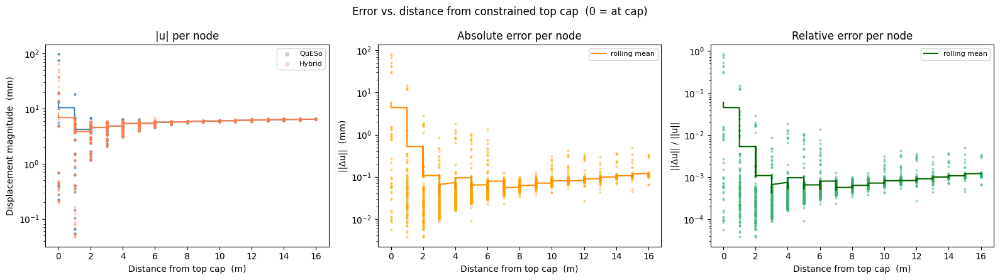

z range: [-8.00, 8.00] m   (cap at z=8.0)


In [154]:
import matplotlib.pyplot as plt

# ── Node z-coordinates and displacement data for active nodes ─────────────────
all_node_coords = case.grid.node_coordinates(poly_order=case.poly_order).cpu().numpy()
active_node_xyz = all_node_coords[active_node_idx]   # (n_active, 3)
z_coords        = active_node_xyz[:, 2]              # z of each active node

u_mag_queso  = nla.norm(uq_act_nodes, axis=1)        # |u_QuESo|  per node
u_mag_hybrid = nla.norm(uh_act_nodes, axis=1)        # |u_Hybrid| per node

# Distance from the constrained top cap  (0 = AT cap,  larger = farther away)
z_cap = z_coords.max()   # top-cap z ≈ +8 m
dist_from_cap = z_cap - z_coords   # ranges from 0 (top) to ~16 (bottom)

# Sort by distance-from-cap for a clean left→right reading
order = np.argsort(dist_from_cap)
dc   = dist_from_cap[order]
umq  = u_mag_queso [order]
umh  = u_mag_hybrid[order]
abse = abs_u_err   [order]
rele = rel_u_err   [order]

# Rolling mean for trend line (window = 5 % of nodes)
from numpy.lib.stride_tricks import sliding_window_view
W = max(1, len(dc) // 20)
pad = W // 2

def roll_mean(x):
    x_pad = np.concatenate([np.full(pad, x[:pad].mean()), x, np.full(W-pad-1, x[-(W-pad-1):].mean())])
    return sliding_window_view(x_pad, W).mean(axis=-1)[:len(x)]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)
fig.suptitle('Error vs. distance from constrained top cap  (0 = at cap)', fontsize=12)

# ── Panel 1: reference displacement magnitude ──────────────────────────────────
ax = axes[0]
ax.scatter(dc, umq  * 1e3, s=4, alpha=0.3, color='steelblue', label='QuESo')
ax.scatter(dc, umh  * 1e3, s=4, alpha=0.3, color='coral',     label='Hybrid')
ax.plot(dc, roll_mean(umq) * 1e3, color='steelblue', lw=1.5)
ax.plot(dc, roll_mean(umh) * 1e3, color='coral',     lw=1.5)
ax.set_xlabel('Distance from top cap  (m)')
ax.set_ylabel('Displacement magnitude  (mm)')
ax.set_title('|u| per node')
ax.set_yscale('log')
ax.legend(fontsize=8, markerscale=2)

# ── Panel 2: absolute displacement error ──────────────────────────────────────
ax = axes[1]
ax.scatter(dc, abse * 1e3, s=4, alpha=0.4, color='orange')
ax.plot(dc, roll_mean(abse) * 1e3, color='darkorange', lw=1.5, label='rolling mean')
ax.set_xlabel('Distance from top cap  (m)')
ax.set_ylabel('||Δu||  (mm)')
ax.set_title('Absolute error per node')
ax.set_yscale('log')
ax.legend(fontsize=8)

# ── Panel 3: relative displacement error ──────────────────────────────────────
ax = axes[2]
ax.scatter(dc, rele, s=4, alpha=0.4, color='mediumseagreen')
ax.plot(dc, roll_mean(rele), color='darkgreen', lw=1.5, label='rolling mean')
ax.set_xlabel('Distance from top cap  (m)')
ax.set_ylabel('||Δu|| / ||u||')
ax.set_title('Relative error per node')
ax.legend(fontsize=8)
ax.set_yscale('log')

fig.tight_layout()
plt.show()

print(f'z range: [{z_coords.min():.2f}, {z_cap:.2f}] m   (cap at z={z_cap:.1f})')

In [79]:
rel

array([0., 0., 0., ..., 0., 0., 0.], shape=(29791,))

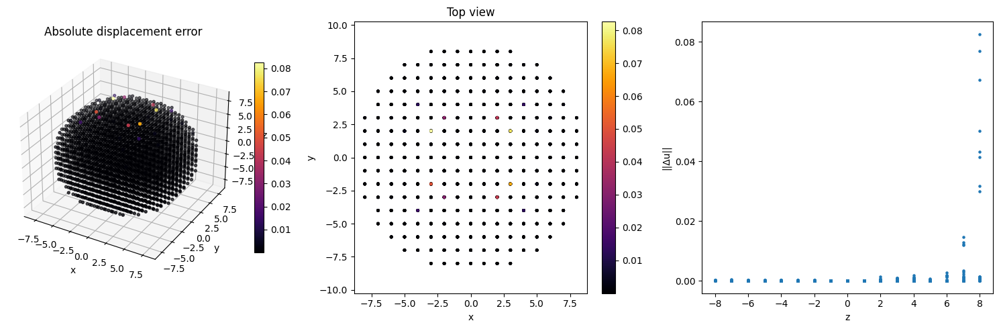

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import numpy.linalg as nla

coords = active_node_xyz

err = abs_u_err

fig = plt.figure(figsize=(15,5))

ax = fig.add_subplot(131, projection="3d")

p = ax.scatter(
    coords[:,0],
    coords[:,1],
    coords[:,2],
    c=err,
    s=8,
    cmap="inferno",
)

ax.set_title("Absolute displacement error")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

plt.colorbar(p, ax=ax, shrink=0.7)

ax = fig.add_subplot(132)

plt.scatter(
    coords[:,0],
    coords[:,1],
    c=err,
    s=6,
    cmap="inferno",
)

plt.axis("equal")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Top view")

plt.colorbar()

ax = fig.add_subplot(133)

plt.scatter(
    coords[:,2],
    err,
    s=5,
)

plt.xlabel("z")
plt.ylabel("||Δu||")

plt.tight_layout()
plt.show()

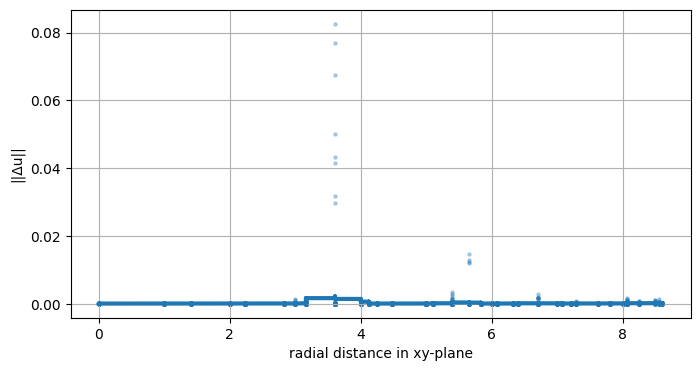

In [36]:
r_xy = np.sqrt(coords[:,0]**2 + coords[:,1]**2)

order = np.argsort(r_xy)

plt.figure(figsize=(8,4))

plt.scatter(
    r_xy[order],
    abs_u_err[order],
    s=5,
    alpha=0.3,
)

from scipy.ndimage import uniform_filter1d

smooth = uniform_filter1d(abs_u_err[order], size=200)

plt.plot(
    r_xy[order],
    smooth,
    lw=3,
)

plt.xlabel("radial distance in xy-plane")
plt.ylabel("||Δu||")

plt.grid(True)

plt.show()

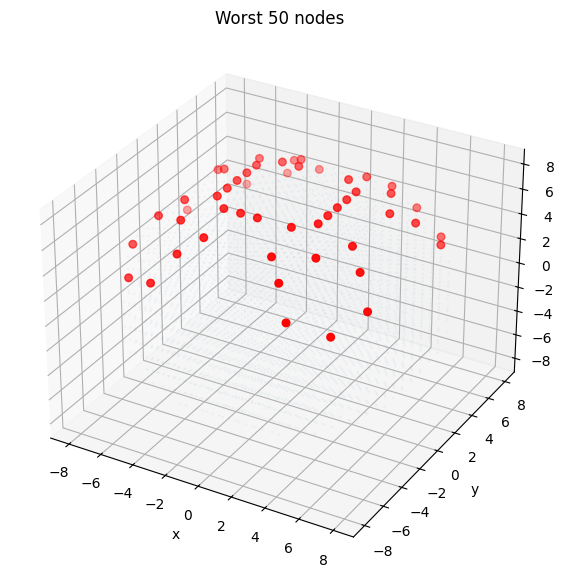

In [37]:
N = 50

idx = np.argsort(abs_u_err)[-N:]

fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(111,projection="3d")

ax.scatter(
    coords[:,0],
    coords[:,1],
    coords[:,2],
    s=1,
    alpha=0.03,
)

ax.scatter(
    coords[idx,0],
    coords[idx,1],
    coords[idx,2],
    c="red",
    s=30,
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title(f"Worst {N} nodes")

plt.show()

In [167]:
rel_u_err = rel

In [171]:
rel_u_err.shape

(2993,)

In [174]:
errs = rel_u_err[rel_u_err > 0]

In [175]:
xs = np.linspace(
    case.grid.bounds[0][0],
    case.grid.bounds[1][0],
    sx
)

ys = np.linspace(
    case.grid.bounds[0][1],
    case.grid.bounds[1][1],
    sy
)

zs = np.linspace(
    case.grid.bounds[0][2],
    case.grid.bounds[1][2],
    sz
)

X,Y,Z = np.meshgrid(
    xs, ys, zs,
    indexing="ij"
)

coords = np.column_stack([
    X.ravel(),
    Y.ravel(),
    Z.ravel()
])

Showing 0 trimmed cells.


ValueError: zero-size array to reduction operation minimum which has no identity

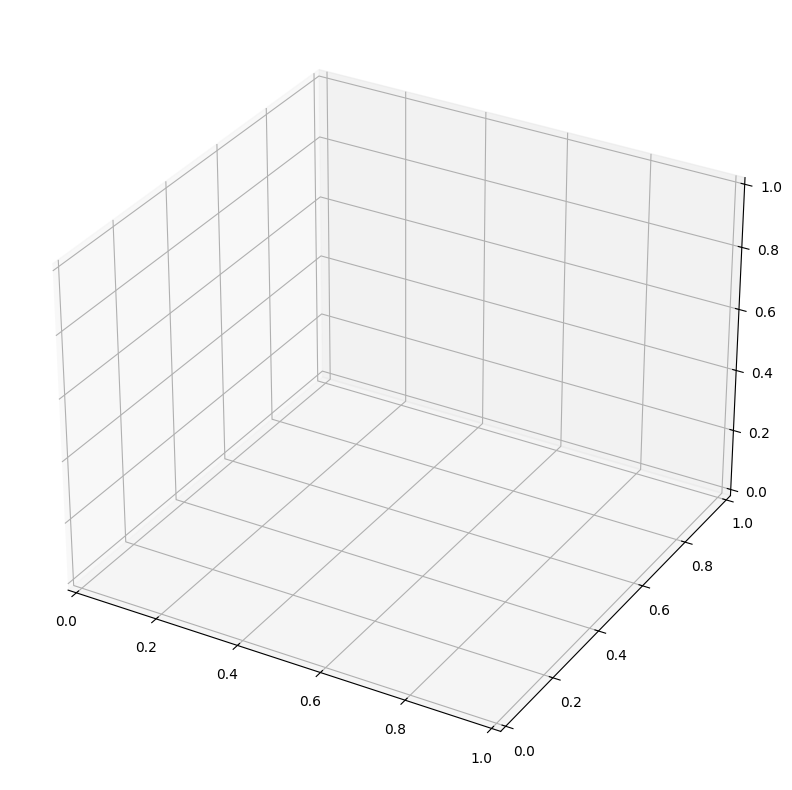

In [176]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from matplotlib import cm

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
R = 7.5
N = 50          # number of worst nodes to inspect

nx, ny, nz = case.grid.resolution
xmin, ymin, zmin = case.grid.bounds[0]
xmax, ymax, zmax = case.grid.bounds[1]

hx = (xmax - xmin) / nx
hy = (ymax - ymin) / ny
hz = (zmax - zmin) / nz

# ------------------------------------------------------------
# Worst nodes
# ------------------------------------------------------------
worst = np.argsort(rel_u_err)[-N:]

# ------------------------------------------------------------
# Collect trimmed cells touching those nodes
# ------------------------------------------------------------
cells = {}

for node in worst:

    # node index -> structured node indices
    k = node % (nz + 1)
    j = (node // (nz + 1)) % (ny + 1)
    i = node // ((ny + 1) * (nz + 1))

    # node belongs to up to 8 neighboring cells
    for di in (-1, 0):
        for dj in (-1, 0):
            for dk in (-1, 0):

                ci = i + di
                cj = j + dj
                ck = k + dk

                if not (0 <= ci < nx and
                        0 <= cj < ny and
                        0 <= ck < nz):
                    continue

                # cube vertices
                V = np.array([
                    [xmin + ci*hx,     ymin + cj*hy,     zmin + ck*hz],
                    [xmin + (ci+1)*hx, ymin + cj*hy,     zmin + ck*hz],
                    [xmin + (ci+1)*hx, ymin + (cj+1)*hy, zmin + ck*hz],
                    [xmin + ci*hx,     ymin + (cj+1)*hy, zmin + ck*hz],
                    [xmin + ci*hx,     ymin + cj*hy,     zmin + (ck+1)*hz],
                    [xmin + (ci+1)*hx, ymin + cj*hy,     zmin + (ck+1)*hz],
                    [xmin + (ci+1)*hx, ymin + (cj+1)*hy, zmin + (ck+1)*hz],
                    [xmin + ci*hx,     ymin + (cj+1)*hy, zmin + (ck+1)*hz],
                ])

                inside = np.linalg.norm(V, axis=1) <= R

                # keep only trimmed cells
                if inside.all() or (~inside).all():
                    continue

                key = (ci, cj, ck)

                if key not in cells:
                    cells[key] = {
                        "verts": V,
                        "err": rel_u_err[node]
                    }
                else:
                    cells[key]["err"] = max(cells[key]["err"], rel_u_err[node])

print(f"Showing {len(cells)} trimmed cells.")

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(111, projection='3d')

errs = np.array([c["err"] for c in cells.values()])
norm = plt.Normalize(errs.min(), errs.max())
cmap = cm.inferno

for cell in cells.values():

    V = cell["verts"]

    faces = [
        [V[q] for q in [0,1,2,3]],
        [V[q] for q in [4,5,6,7]],
        [V[q] for q in [0,1,5,4]],
        [V[q] for q in [1,2,6,5]],
        [V[q] for q in [2,3,7,6]],
        [V[q] for q in [3,0,4,7]],
    ]

    poly = Poly3DCollection(
        faces,
        facecolor=cmap(norm(cell["err"])),
        edgecolor="k",
        linewidth=0.4,
        alpha=0.9,
    )

    ax.add_collection3d(poly)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_zlim(zmin, zmax)
ax.set_box_aspect((1,1,1))

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Trimmed cells containing the worst displacement nodes")

sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, ax=ax, shrink=0.7, label="Displacement error")

plt.tight_layout()
plt.show()

ax.add_collection3d(poly)

ax.set_xlim(-9,9)
ax.set_ylim(-9,9)
ax.set_zlim(-9,9)
ax.set_box_aspect((1,1,1))

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Trimmed cells containing the worst-displacement nodes")

plt.show()

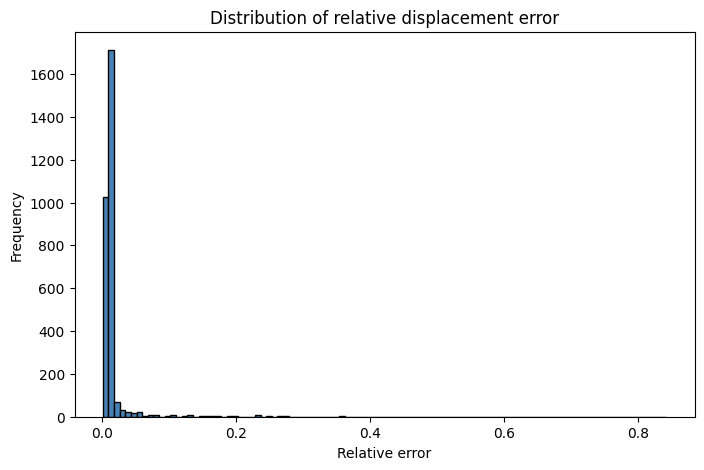

In [95]:
#plot distribution of relative error
rel_err_np = rel_u_err[(rel_u_err > 1e-6) ]  # filter out very small errors for better visualization
plt.figure(figsize=(8,5))
plt.hist(rel_err_np, bins=100, color='steelblue', edgecolor='black')
plt.title("Distribution of relative displacement error")
plt.xlabel("Relative error")
plt.ylabel("Frequency")
plt.show()

In [98]:
rel_ke_err_np

array([0.10452567, 0.06078499, 0.05579248, ..., 0.04991445, 0.06654868,
       0.03928607], shape=(1016,))

Worst cut configurations:
  0  relKe=1.090e-01  MC index=  1
  1  relKe=1.045e-01  MC index= 64
  2  relKe=9.082e-02  MC index=  8
  3  relKe=8.956e-02  MC index=  2
  4  relKe=8.955e-02  MC index=  2
  5  relKe=8.890e-02  MC index=191
  6  relKe=8.813e-02  MC index=204
  7  relKe=8.704e-02  MC index=114
  8  relKe=8.648e-02  MC index=220
  9  relKe=8.583e-02  MC index=204
 10  relKe=8.524e-02  MC index=114
 11  relKe=8.154e-02  MC index= 64
 12  relKe=8.123e-02  MC index= 76
 13  relKe=7.672e-02  MC index=243
 14  relKe=7.423e-02  MC index=102
 15  relKe=7.377e-02  MC index=224
 16  relKe=7.352e-02  MC index=128
 17  relKe=7.348e-02  MC index=187
 18  relKe=7.304e-02  MC index=243
 19  relKe=7.298e-02  MC index=252
 20  relKe=7.275e-02  MC index=223
 21  relKe=7.118e-02  MC index=  2
 22  relKe=7.059e-02  MC index=128
 23  relKe=6.834e-02  MC index=240
 24  relKe=6.792e-02  MC index=136
 25  relKe=6.655e-02  MC index=155
 26  relKe=6.618e-02  MC index=247
 27  relKe=6.615e-02  MC inde

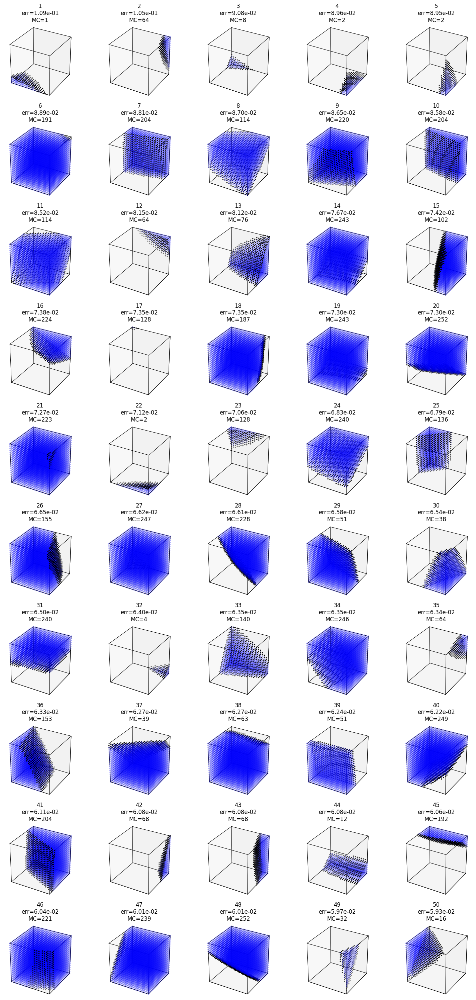

In [144]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------
# Parameters
# -------------------------------------------------------

R = 7.5
Nworst = 50

nx, ny, nz = case.grid.resolution

xmin, ymin, zmin = case.grid.bounds[0]
xmax, ymax, zmax = case.grid.bounds[1]

hx = (xmax-xmin)/nx
hy = (ymax-ymin)/ny
hz = (zmax-zmin)/nz


corner_offsets = np.array([
    [0,0,0],
    [1,0,0],
    [1,1,0],
    [0,1,0],
    [0,0,1],
    [1,0,1],
    [1,1,1],
    [0,1,1],
])


# -------------------------------------------------------
# Cut cell indices
# -------------------------------------------------------

partial_array = np.array(list(partial_set))

# sort so the indexing matches the cut-cell dataset
partial_array = np.sort(partial_array)

worst = np.argsort(rel_ke_err_np)[-Nworst:][::-1]


cells = []

for w in worst:

    cell_id = partial_array[w]

    # linear cell id -> (i,j,k)
    k = cell_id % nz
    j = (cell_id // nz) % ny
    i = cell_id // (ny*nz)

    origin = np.array([
        xmin+i*hx,
        ymin+j*hy,
        zmin+k*hz
    ])

    verts = origin + corner_offsets*np.array([
        hx,hy,hz
    ])

    sdf = np.linalg.norm(verts,axis=1)-R

    inside = sdf <= 0

    mc_index = sum(
        (1<<m)
        for m in range(8)
        if inside[m]
    )

    cells.append({
        "origin":origin,
        "mc":mc_index,
        "err":rel_ke_err_np[w],
        "inside":inside
    })


print("Worst cut configurations:")
for n,c in enumerate(cells):
    print(
        f"{n:3d}  relKe={c['err']:.3e}  MC index={c['mc']:3d}"
    )


# -------------------------------------------------------
# Visualization
# -------------------------------------------------------

def draw_cube(ax):

    edges=[
        (0,1),(1,2),(2,3),(3,0),
        (4,5),(5,6),(6,7),(7,4),
        (0,4),(1,5),(2,6),(3,7)
    ]

    V=np.array([
        [0,0,0],[1,0,0],[1,1,0],[0,1,0],
        [0,0,1],[1,0,1],[1,1,1],[0,1,1]
    ])

    for a,b in edges:
        ax.plot(
            [V[a,0],V[b,0]],
            [V[a,1],V[b,1]],
            [V[a,2],V[b,2]],
            "k",
            linewidth=0.8
        )


def draw_cut(ax, cell):

    origin = cell["origin"]

    n = 20

    xs=np.linspace(origin[0],origin[0]+hx,n)
    ys=np.linspace(origin[1],origin[1]+hy,n)
    zs=np.linspace(origin[2],origin[2]+hz,n)

    X,Y,Z=np.meshgrid(xs,ys,zs,indexing="ij")

    F=np.sqrt(X**2+Y**2+Z**2)-R

    # inside material
    inside = F <= 0

    if np.any(inside):

        pts=np.column_stack([
            (X[inside]-origin[0])/hx,
            (Y[inside]-origin[1])/hy,
            (Z[inside]-origin[2])/hz
        ])

        ax.scatter(
            pts[:,0],
            pts[:,1],
            pts[:,2],
            s=5,
            alpha=0.25,
            color="blue"
        )

    # interface
    surf=np.abs(F)<0.03

    if np.any(surf):

        pts=np.column_stack([
            (X[surf]-origin[0])/hx,
            (Y[surf]-origin[1])/hy,
            (Z[surf]-origin[2])/hz
        ])

        ax.scatter(
            pts[:,0],
            pts[:,1],
            pts[:,2],
            s=3,
            color="black"
        )


# gallery

cols=5
rows=int(np.ceil(len(cells)/cols))

fig=plt.figure(figsize=(15,3*rows))

for n,cell in enumerate(cells):

    ax=fig.add_subplot(
        rows,
        cols,
        n+1,
        projection="3d"
    )

    draw_cube(ax)
    draw_cut(ax,cell)

    ax.set_xlim(0,1)
    ax.set_ylim(0,1)
    ax.set_zlim(0,1)

    ax.set_box_aspect((1,1,1))

    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_zticks([])

    ax.set_title(
        f"{n+1}\nerr={cell['err']:.2e}\nMC={cell['mc']}"
    )


plt.tight_layout()
plt.show()

In [116]:
print(len(partial))
print(type(partial))
print(partial[:5])

30
<class 'torch.Tensor'>
tensor([[[False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         ...,
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False]],

        [[False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         ...,
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False]],

        [[False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         ...,
         [False, False, False,  ..., False,

In [163]:
import numpy as np
import matplotlib.pyplot as plt


# -------------------------------------------------------
# Parameters
# -------------------------------------------------------

R = 7.5
Nworst = 100

nx, ny, nz = case.grid.resolution

xmin, ymin, zmin = case.grid.bounds[0]
xmax, ymax, zmax = case.grid.bounds[1]

hx = (xmax-xmin)/nx
hy = (ymax-ymin)/ny
hz = (zmax-zmin)/nz


# -------------------------------------------------------
# Cell corner convention
# -------------------------------------------------------

corner_offsets = np.array([
    [0,0,0],
    [1,0,0],
    [1,1,0],
    [0,1,0],
    [0,0,1],
    [1,0,1],
    [1,1,1],
    [0,1,1],
])


# -------------------------------------------------------
# Helper functions
# -------------------------------------------------------

def get_cell_data(ci,cj,ck):

    origin=np.array([
        xmin+ci*hx,
        ymin+cj*hy,
        zmin+ck*hz
    ])

    verts = origin + corner_offsets*np.array(
        [hx,hy,hz]
    )


    sdf = np.linalg.norm(
        verts,
        axis=1
    ) - R


    inside = sdf <= 0


    # not trimmed
    if inside.all() or (~inside).all():
        return None


    mc_index = sum(
        (1<<m)
        for m in range(8)
        if inside[m]
    )


    return {
        "origin": origin,
        "verts": verts,
        "sdf": sdf,
        "mc": mc_index
    }



def draw_cube(ax, origin):

    verts = origin + corner_offsets*np.array(
        [hx,hy,hz]
    )


    edges=[
        (0,1),(1,2),(2,3),(3,0),
        (4,5),(5,6),(6,7),(7,4),
        (0,4),(1,5),(2,6),(3,7)
    ]


    for a,b in edges:

        ax.plot(
            [verts[a,0],verts[b,0]],
            [verts[a,1],verts[b,1]],
            [verts[a,2],verts[b,2]],
            "k",
            linewidth=0.8
        )



def draw_inside(ax, cell):

    origin = cell["origin"]

    n = 12

    x=np.linspace(
        origin[0],
        origin[0]+hx,
        n
    )

    y=np.linspace(
        origin[1],
        origin[1]+hy,
        n
    )

    z=np.linspace(
        origin[2],
        origin[2]+hz,
        n
    )


    X,Y,Z=np.meshgrid(
        x,y,z,
        indexing="ij"
    )


    F=np.sqrt(
        X**2+Y**2+Z**2
    )-R


    inside = F <= 0


    pts=np.column_stack([
        X[inside],
        Y[inside],
        Z[inside]
    ])


    if len(pts):

        ax.scatter(
            pts[:,0],
            pts[:,1],
            pts[:,2],
            s=5,
            alpha=0.3,
            color="royalblue"
        )


    # interface points

    surface=np.abs(F)<0.05*hx


    pts=np.column_stack([
        X[surface],
        Y[surface],
        Z[surface]
    ])


    if len(pts):

        ax.scatter(
            pts[:,0],
            pts[:,1],
            pts[:,2],
            s=3,
            color="black",
            alpha=0.3
        )



# -------------------------------------------------------
# Find worst nodes and their neighboring cut cells
# -------------------------------------------------------

worst_nodes = np.argsort(rel_u_err)[-Nworst:]


bad_configurations=[]


for n in worst_nodes[::-1]:

    x,y,z = coords[n]


    i=int(round((x-xmin)/hx))
    j=int(round((y-ymin)/hy))
    k=int(round((z-zmin)/hz))
    if not (0 <= i <= nx and 0 <= j <= ny and 0 <= k <= nz):
        print(n, x, y, z, i, j, k)

    cells=[]


    # 8 neighboring cells
    for di in [-1,0]:
        for dj in [-1,0]:
            for dk in [-1,0]:

                ci=i+di
                cj=j+dj
                ck=k+dk


                if (
                    ci<0 or cj<0 or ck<0 or
                    ci>=nx or cj>=ny or ck>=nz
                ):
                    continue


                cell=get_cell_data(
                    ci,cj,ck
                )


                if cell is not None:
                    cells.append(cell)



    if len(cells):

        bad_configurations.append({
            "node": n,
            "error": rel_u_err[n],
            "cells": cells
        })



print(
    "Number of bad node configurations:",
    len(bad_configurations)
)



# -------------------------------------------------------
# Plot grouped configurations
# -------------------------------------------------------

nplot=min(
    len(bad_configurations),
    Nworst
)


cols=5
rows=int(np.ceil(nplot/cols))


fig=plt.figure(
    figsize=(15,3*rows)
)


for a,conf in enumerate(
    bad_configurations[:nplot]
):

    ax=fig.add_subplot(
        rows,
        cols,
        a+1,
        projection="3d"
    )


    # draw all neighboring cut cells
    for cell in conf["cells"]:

        draw_cube(
            ax,
            cell["origin"]
        )

        draw_inside(
            ax,
            cell
        )


    # problematic node
    p=coords[conf["node"]]


    ax.scatter(
        [p[0]],
        [p[1]],
        [p[2]],
        s=80,
        color="red"
    )


    mc_classes=[
        c["mc"]
        for c in conf["cells"]
    ]


    ax.set_title(
        f"err={conf['error']:.2e}\n"
        f"cells={len(mc_classes)}\n"
        f"MC={mc_classes}"
    )


    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_zticks([])

    ax.set_box_aspect(
        [1,1,1]
    )


plt.tight_layout()
plt.show()

Number of bad node configurations: 0


<Figure size 1500x0 with 0 Axes>

In [178]:
count = 0

for ci in range(nx):
    for cj in range(ny):
        for ck in range(nz):

            origin = np.array([
                xmin + ci*hx,
                ymin + cj*hy,
                zmin + ck*hz
            ])

            verts = origin + corner_offsets*np.array([hx,hy,hz])

            inside = np.linalg.norm(verts, axis=1) <= R

            if not (inside.all() or (~inside).all()):
                count += 1

print(count)

1064



 max surrounding K error
Pearson : 0.1858390521105795
Spearman: 0.2483712510365349

 average surrounding K error
Pearson : 0.3549986152903554
Spearman: 0.40295155753514933


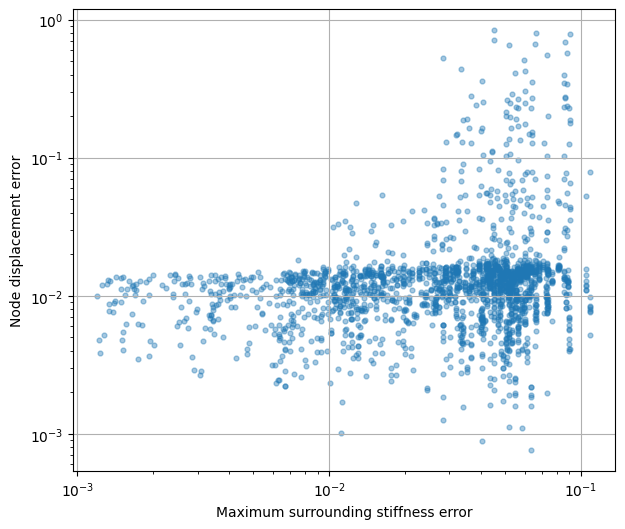

In [134]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr


# -------------------------------------------------------
# Mesh
# -------------------------------------------------------

nx, ny, nz = case.grid.resolution

sx = nx + 1
sy = ny + 1
sz = nz + 1


def node_id(i,j,k):
    return i*(sy*sz) + j*sz + k



# -------------------------------------------------------
# Convert active cells
# -------------------------------------------------------

cell_ids = (
    queso_active
    .detach()
    .cpu()
    .numpy()
    .astype(int)
)

assert len(cell_ids) == len(rel_ke_err_np)


# -------------------------------------------------------
# Accumulate K errors onto nodes
# -------------------------------------------------------

node_K_values = [[] for _ in range(sx*sy*sz)]


for cell_id, kerr in zip(cell_ids, rel_ke_err_np):

    k = cell_id % nz
    j = (cell_id // nz) % ny
    i = cell_id // (ny*nz)


    # add this cell K error to its 8 nodes
    for di in [0,1]:
        for dj in [0,1]:
            for dk in [0,1]:

                nid = node_id(
                    i+di,
                    j+dj,
                    k+dk
                )

                node_K_values[nid].append(kerr)



# -------------------------------------------------------
# Node stiffness error measures
# -------------------------------------------------------

node_K_max = np.zeros(sx*sy*sz)
node_K_avg = np.zeros(sx*sy*sz)


for n, values in enumerate(node_K_values):

    if len(values):

        node_K_max[n] = np.max(values)
        node_K_avg[n] = np.mean(values)



# -------------------------------------------------------
# Correlation with displacement
# -------------------------------------------------------

valid = np.array(
    [len(v)>0 for v in node_K_values]
)

u = rel_u_err[valid]

Kmax = node_K_max[valid]
Kavg = node_K_avg[valid]


for name,K in [
    ("max surrounding K error", Kmax),
    ("average surrounding K error", Kavg)
]:

    pear = pearsonr(K,u)
    spear = spearmanr(K,u)

    print("\n",name)
    print("Pearson :", pear.statistic)
    print("Spearman:", spear.statistic)



# -------------------------------------------------------
# Plot best candidate
# -------------------------------------------------------

plt.figure(figsize=(7,6))

plt.scatter(
    Kmax,
    u,
    s=12,
    alpha=0.4
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel(
    "Maximum surrounding stiffness error"
)

plt.ylabel(
    "Node displacement error"
)

plt.grid(True)

plt.show()

Cell K error:
 min = 0.0011983287500032704
 max = 0.10899969401561053
 mean = 0.019720519442729983

Node max surrounding K error:
 min = 0.0011983287500032704
 max = 0.10899969401561053
 mean = 0.03701503056082762


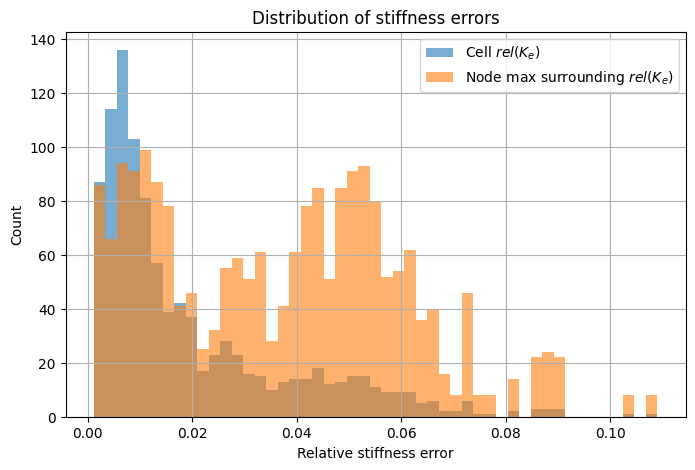

In [138]:
import numpy as np
import matplotlib.pyplot as plt


# -------------------------------------------------------
# Distributions
# -------------------------------------------------------

cell_K = rel_ke_err_np

node_K = node_K_max[valid]


print("Cell K error:")
print(" min =", cell_K.min())
print(" max =", cell_K.max())
print(" mean =", cell_K.mean())

print("\nNode max surrounding K error:")
print(" min =", node_K.min())
print(" max =", node_K.max())
print(" mean =", node_K.mean())


# -------------------------------------------------------
# Histogram (log scale)
# -------------------------------------------------------

plt.figure(figsize=(8,5))

bins = np.linspace(
    min(cell_K.min(), node_K.min()),
    max(cell_K.max(), node_K.max()),
    50
)

plt.hist(
    cell_K,
    bins=bins,
    alpha=0.6,
    label="Cell $rel(K_e)$"
)

plt.hist(
    node_K,
    bins=bins,
    alpha=0.6,
    label="Node max surrounding $rel(K_e)$"
)


plt.xlabel(
    "Relative stiffness error"
)

plt.ylabel(
    "Count"
)

plt.title(
    "Distribution of stiffness errors"
)

plt.legend()
plt.grid(True)

plt.show()

In [179]:
import numpy as np


# -------------------------------------------------------
# Prepare data
# -------------------------------------------------------

points = coords.astype(float)

u_queso = uq.reshape(-1,3)
u_nn = uh.reshape(-1,3)

u_error = (u_nn - u_queso)
# mesh resolution
nx, ny, nz = case.grid.resolution


# -------------------------------------------------------
# Hex connectivity
# -------------------------------------------------------

hexes = []

def nid(i,j,k):
    return i*(ny+1)*(nz+1) + j*(nz+1) + k


for i in range(nx):
    for j in range(ny):
        for k in range(nz):

            hexes.append([
                nid(i,j,k),
                nid(i+1,j,k),
                nid(i+1,j+1,k),
                nid(i,j+1,k),
                nid(i,j,k+1),
                nid(i+1,j,k+1),
                nid(i+1,j+1,k+1),
                nid(i,j+1,k+1)
            ])

hexes = np.asarray(hexes)



# -------------------------------------------------------
# Write legacy VTK
# -------------------------------------------------------

filename = "sphere_displacements.vtk"


with open(filename,"w") as f:

    f.write("# vtk DataFile Version 3.0\n")
    f.write("Sphere displacement comparison\n")
    f.write("ASCII\n")
    f.write("DATASET UNSTRUCTURED_GRID\n\n")


    # points
    f.write(f"POINTS {len(points)} float\n")

    for p in points:
        f.write(
            f"{p[0]} {p[1]} {p[2]}\n"
        )


    # cells
    ncell = len(hexes)

    f.write("\n")
    f.write(
        f"CELLS {ncell} {ncell*9}\n"
    )

    for h in hexes:
        f.write(
            "8 "
            + " ".join(map(str,h))
            + "\n"
        )


    # cell types
    f.write("\n")
    f.write(
        f"CELL_TYPES {ncell}\n"
    )

    # VTK_HEXAHEDRON = 12
    for _ in range(ncell):
        f.write("12\n")


    # point data
    f.write("\n")
    f.write(
        f"POINT_DATA {len(points)}\n"
    )


    def write_vector(name, data):

        f.write("\n")
        f.write(
            f"VECTORS {name} float\n"
        )

        for v in data:
            f.write(
                f"{v[0]} {v[1]} {v[2]}\n"
            )


    write_vector(
        "u_QuESo",
        u_queso
    )

    write_vector(
        "u_NN",
        u_nn
    )

    write_vector(
        "u_error",
        u_error
    )


print("written:", filename)

written: sphere_displacements.vtk


In [124]:
rel_ke_err_np.shape

(1016,)

In [125]:
cell_indices.shape

torch.Size([3, 1064])

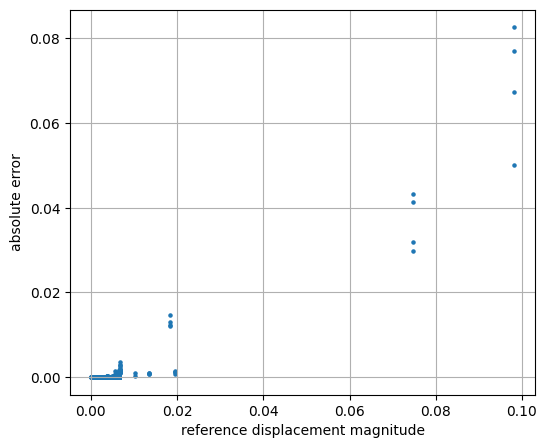

In [38]:
u_mag = nla.norm(uq_act_nodes,axis=1)

plt.figure(figsize=(6,5))

plt.scatter(
    u_mag,
    abs_u_err,
    s=5,
)

plt.xlabel("reference displacement magnitude")
plt.ylabel("absolute error")

plt.grid(True)

plt.show()

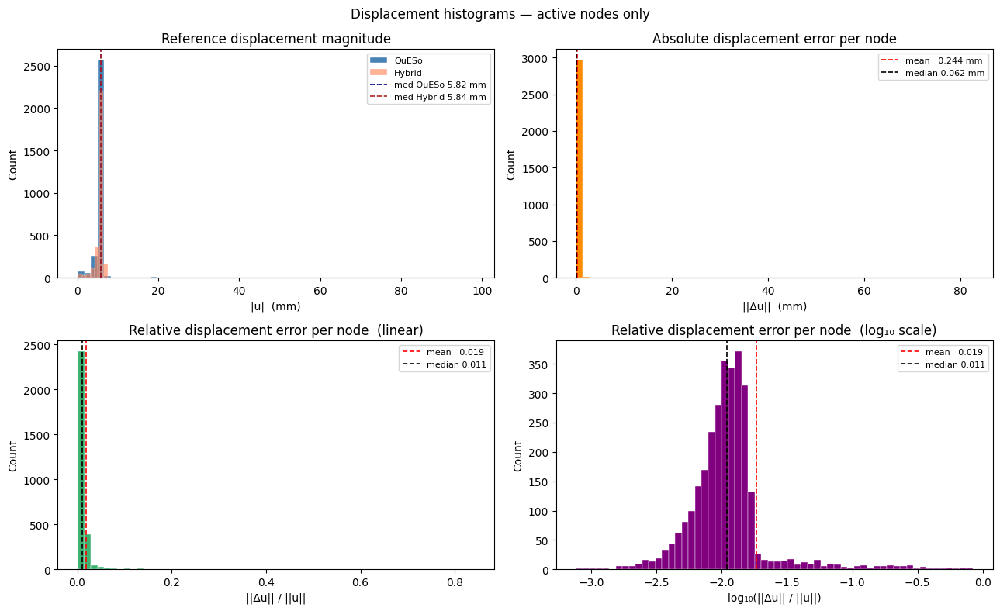

Absolute error: min=0.004 mm  mean=0.244 mm  median=0.062 mm  max=82.608 mm
Relative error: min=0.0008  mean=0.0185  median=0.0109  max=0.8418


In [39]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
fig.suptitle('Displacement histograms — active nodes only', fontsize=12)

# ── Reference displacement |u_queso| ─────────────────────────────────────────
ax = axes[0, 0]
ax.hist(u_mag_queso * 1e3, bins=60, color='steelblue', edgecolor='white', lw=0.3, label='QuESo')
ax.hist(u_mag_hybrid * 1e3, bins=60, color='coral', edgecolor='white', lw=0.3, alpha=0.6, label='Hybrid')
ax.axvline(np.median(u_mag_queso) * 1e3, color='navy',   ls='--', lw=1.2, label=f'med QuESo {np.median(u_mag_queso)*1e3:.2f} mm')
ax.axvline(np.median(u_mag_hybrid) * 1e3, color='firebrick', ls='--', lw=1.2, label=f'med Hybrid {np.median(u_mag_hybrid)*1e3:.2f} mm')
ax.set_xlabel('|u|  (mm)')
ax.set_ylabel('Count')
ax.set_title('Reference displacement magnitude')
ax.legend(fontsize=8)

# ── Absolute error |Δu| ───────────────────────────────────────────────────────
ax = axes[0, 1]
ax.hist(abs_u_err * 1e3, bins=60, color='darkorange', edgecolor='white', lw=0.3)
ax.axvline(np.mean  (abs_u_err) * 1e3, color='red',    ls='--', lw=1.2, label=f'mean   {np.mean(abs_u_err)*1e3:.3f} mm')
ax.axvline(np.median(abs_u_err) * 1e3, color='black',  ls='--', lw=1.2, label=f'median {np.median(abs_u_err)*1e3:.3f} mm')
ax.set_xlabel('||Δu||  (mm)')
ax.set_ylabel('Count')
ax.set_title('Absolute displacement error per node')
ax.legend(fontsize=8)

# ── Relative error |Δu| / |u_queso| — linear scale ────────────────────────────
ax = axes[1, 0]
finite = rel_u_err[np.isfinite(rel_u_err)]
ax.hist(finite, bins=60, color='mediumseagreen', edgecolor='white', lw=0.3)
ax.axvline(np.mean  (finite), color='red',   ls='--', lw=1.2, label=f'mean   {np.mean(finite):.3f}')
ax.axvline(np.median(finite), color='black', ls='--', lw=1.2, label=f'median {np.median(finite):.3f}')
ax.set_xlabel('||Δu|| / ||u||')
ax.set_ylabel('Count')
ax.set_title('Relative displacement error per node  (linear)')
ax.legend(fontsize=8)

# ── Relative error — log scale ─────────────────────────────────────────────────
ax = axes[1, 1]
log_rel = np.log10(finite + 1e-12)
ax.hist(log_rel, bins=60, color='purple', edgecolor='white', lw=0.3)
ax.axvline(np.log10(np.mean  (finite)), color='red',   ls='--', lw=1.2, label=f'mean   {np.mean(finite):.3f}')
ax.axvline(np.log10(np.median(finite)), color='black', ls='--', lw=1.2, label=f'median {np.median(finite):.3f}')
ax.set_xlabel('log₁₀(||Δu|| / ||u||)')
ax.set_ylabel('Count')
ax.set_title('Relative displacement error per node  (log₁₀ scale)')
ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

print(f'Absolute error: min={abs_u_err.min()*1e3:.3f} mm  mean={abs_u_err.mean()*1e3:.3f} mm  '
      f'median={np.median(abs_u_err)*1e3:.3f} mm  max={abs_u_err.max()*1e3:.3f} mm')
print(f'Relative error: min={finite.min():.4f}  mean={finite.mean():.4f}  '
      f'median={np.median(finite):.4f}  max={finite.max():.4f}')

In [40]:
import itertools
import torch
from internal_nn_runtime.cutcell_ml.model import build_rigid_body_modes

def find_true_corner_ordering(k_ref_sample: torch.Tensor, base_coords: torch.Tensor):
    """
    k_ref_sample: (24,24) ground-truth stiffness matrix (ideally from a
                  cell far from any near-degenerate cut, e.g. an
                  uncut/mostly-solid sample, for a clean null space).
    base_coords:  (8,3) some assumed coordinate set, e.g. HEX_CORNER_COORDS
                  -- only used as the *set* of 8 points; we search over
                  which physical point maps to which dof-block index.

    Returns the corner ordering (as a coords tensor) whose induced R best
    aligns with k_ref_sample's true (numerically) rigid-body subspace.
    """
    evals, evecs = torch.linalg.eigh(k_ref_sample.double())
    null_space = evecs[:, :6]  # (24,6), the true rigid-body subspace
    P_null = null_space @ null_space.T  # projector onto it

    best_perm, best_resid = None, float("inf")
    for perm in itertools.permutations(range(8)):
        coords = base_coords[list(perm)]
        R = build_rigid_body_modes(coords).double()  # (24,6)
        # How much of R's rotation part lies OUTSIDE the true null space?
        resid = (R - P_null @ R).norm().item()
        if resid < best_resid:
            best_resid, best_perm = resid, perm

    return best_perm, best_resid, base_coords[list(best_perm)]

In [41]:
HEX_CORNER_COORDS = torch.tensor(
    [
        (-1., -1., -1.),
        ( 1., -1., -1.),
        ( 1.,  1., -1.),
        (-1.,  1., -1.),
        (-1., -1.,  1.),
        ( 1., -1.,  1.),
        ( 1.,  1.,  1.),
        (-1.,  1.,  1.),
    ],
    dtype=torch.float32,
)


In [42]:
# find_true_corner_ordering(ke_queso[0], HEX_CORNER_COORDS)

In [43]:
ke_queso[0].shape

torch.Size([24, 24])

In [44]:
from clean_simulation.internal_nn_runtime.cutcell_ml.model import (
    CutCellNet, build_null_space_basis, HEX_CORNER_COORDS,
)

T_true = build_null_space_basis(HEX_CORNER_COORDS)   # (24, 18)

model = CutCellNet()
print(torch.allclose(model.null_basis, T_true, atol=1e-5))
print((model.null_basis - T_true).abs().max().item())

True
0.0


In [45]:
# for e in attached_trimmed:

#     print(torch.norm(
#         ke_nn[e]-ke_queso[e]
#     )/torch.norm(ke_queso[e]))

In [46]:
model = CutCellNet()
model.eval()

d = torch.randn(4, 8)  # random SDF, doesn't matter -- untrained weights are also random
with torch.no_grad():
    K_unit, log_norm = model(d)
    K = K_unit * torch.exp(log_norm)[:, None, None]

R = build_rigid_body_modes(HEX_CORNER_COORDS).to(K.dtype)  # the CONFIRMED-correct R
resid = (K @ R).abs().max().item()
print("K @ R residual:", resid)

evals = torch.linalg.eigvalsh(K[0].double())
print(evals[:8])  # first 8, ascending -- expect first 6 near 0

K @ R residual: 4.3958425521850586e-07
tensor([-7.3373e-08, -4.9394e-08, -2.0466e-08, -1.3508e-08,  1.6458e-09,
         2.8651e-08,  4.4159e-08,  2.9480e-06], dtype=torch.float64)


Benchmark dataset  : 1016 cells × 171 Cholesky params
  Loaded 5 samples from _tmp_no_queso.h5 / depth_2_integration_2_poly_1
  skip local_stiffness_matrices_queso_i2_p1.h5: [enforce fail at alloc_cpu.cpp:117] data. DefaultCPUAllocator: not enough memory: you tried to allocate 18967527936 bytes.
  Loaded 603,285 samples from naive_stiffness_matrices_queso_i2_p1.h5 / integration_2_poly_1
Full training set  : 603,290 cells × 171 Cholesky params

── PCA: benchmark (1,016 samples) ─────────────────────
  Cholesky dims : 171
  99.000% variance →   4 PCs  (2.3%)
  99.900% variance →   8 PCs  (4.7%)
  99.990% variance →  15 PCs  (8.8%)
  99.999% variance →  18 PCs  (10.5%)
  Top-5 singular values: [17629259.89769945  4242885.87209451  4195507.65027892  3776432.17072609
   940530.18407886]

── PCA: full training set (603,290 samples) ─────────────────────
  Cholesky dims : 171
  99.000% variance →   4 PCs  (2.3%)
  99.900% variance →   9 PCs  (5.3%)
  99.990% variance →  14 PCs  (8.2%)
  99.99

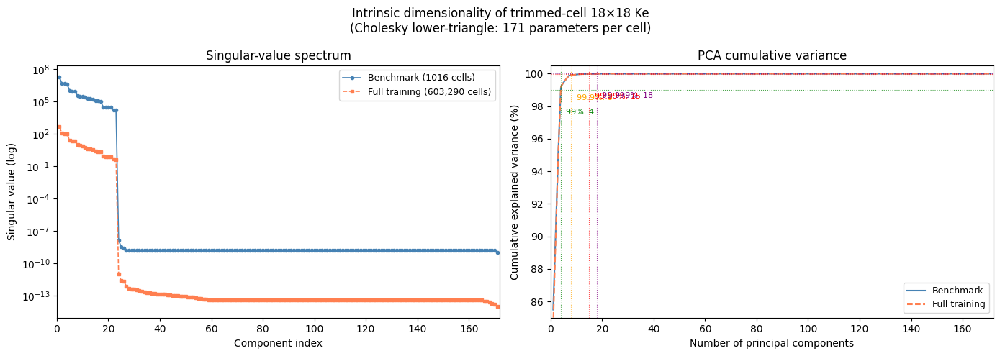


── Compression summary ──────────────────────────────────
  99.000% variance →   4 PCs  (171 → 4, 2% of params)
  99.900% variance →   8 PCs  (171 → 8, 5% of params)
  99.990% variance →  15 PCs  (171 → 15, 9% of params)
  99.999% variance →  18 PCs  (171 → 18, 11% of params)

Conclusion: 8 PCs capture 99.9% of variance  → NN head could output 8 scalars instead of 171.


In [47]:

# ── Intrinsic dimensionality of trimmed-cell stiffness matrices ───────────────
#
# 1. Project each 24×24 Ke → 18×18 via the null-space basis T
# 2. Flatten lower triangle → 171-dim Cholesky vector
# 3. PCA (SVD) on the N × 171 matrix
# 4. Plot spectrum + cumulative variance; report break-even thresholds

import matplotlib.pyplot as plt
import numpy as np
import torch
import h5py

# ── Null-space basis T (24, 18) ───────────────────────────────────────────────
from clean_simulation.internal_nn_runtime.cutcell_ml.model import NULL_SPACE_BASIS
T = NULL_SPACE_BASIS.double().cpu()    # (24, 18)

def project_to_18(ke24: torch.Tensor) -> torch.Tensor:
    """(N, 24, 24) → (N, 18, 18) via T.T @ Ke @ T."""
    return T.T @ ke24 @ T

def lower_tri_flat(ke18: torch.Tensor) -> torch.Tensor:
    """(N, 18, 18) → (N, 171)  lower-triangle incl. diagonal."""
    r, c = torch.tril_indices(18, 18)
    return ke18[:, r, c]

def ut_to_full_24(ut: np.ndarray) -> torch.Tensor:
    """(N, 300) upper-triangle → (N, 24, 24) symmetric tensor."""
    N   = ut.shape[0]
    r, c = torch.triu_indices(24, 24)
    K   = torch.zeros(N, 24, 24, dtype=torch.float64)
    K[:, r, c] = torch.tensor(ut, dtype=torch.float64)
    K   = K + K.transpose(-1, -2) - torch.diag_embed(K.diagonal(dim1=-2, dim2=-1))
    return K

# ── (a) Benchmark cells (ke_queso already in memory) ─────────────────────────
ke18_bench = project_to_18(ke_queso.double())
X_bench    = lower_tri_flat(ke18_bench).numpy()
print(f'Benchmark dataset  : {X_bench.shape[0]} cells × {X_bench.shape[1]} Cholesky params')

# ── (b) Full training dataset from HDF5 ──────────────────────────────────────
data_dir = root / 'clean_simulation' / 'outputs' / 'data'
h5_files  = sorted(data_dir.glob('*queso*.h5'))
if not h5_files:
    h5_files = sorted(data_dir.glob('*.h5'))

K_all = []
for h5_p in h5_files:
    try:
        with h5py.File(h5_p, 'r') as f:
            for grp_name in ['integration_2_poly_1',
                             'depth_4_integration_2_poly_1',
                             'depth_2_integration_2_poly_1']:
                if grp_name not in f:
                    continue
                grp = f[grp_name]
                if 'stiffness_ut' in grp:          # stored as (N, 300) upper-triangle
                    ut  = grp['stiffness_ut'][:]
                    K24 = ut_to_full_24(ut)
                elif 'k_matrices' in grp:           # stored as (N, 24, 24) full
                    K24 = torch.tensor(grp['k_matrices'][:], dtype=torch.float64)
                else:
                    continue
                K_all.append(K24)
                print(f'  Loaded {K24.shape[0]:,} samples from {h5_p.name} / {grp_name}')
                break
    except Exception as e:
        print(f'  skip {h5_p.name}: {e}')

if K_all:
    K_full    = torch.cat(K_all, dim=0)
    ke18_full = project_to_18(K_full)
    X_full    = lower_tri_flat(ke18_full).numpy()
    print(f'Full training set  : {X_full.shape[0]:,} cells × {X_full.shape[1]} Cholesky params')
else:
    print('No HDF5 training data found — using benchmark cells only.')
    X_full = X_bench

# ── PCA via thin SVD ──────────────────────────────────────────────────────────
def run_pca(X: np.ndarray, label: str):
    Xc = X - X.mean(axis=0, keepdims=True)
    if Xc.shape[0] >= Xc.shape[1]:
        _, s, _ = np.linalg.svd(Xc, full_matrices=False)
    else:
        G      = Xc @ Xc.T
        ev, _  = np.linalg.eigh(G)
        s      = np.sqrt(np.clip(ev[::-1], 0, None))

    var = s**2 / (s**2).sum()
    cum = np.cumsum(var)
    thresholds = [0.99, 0.999, 0.9999, 0.99999]
    nc = {t: int(np.searchsorted(cum, t)) + 1 for t in thresholds}

    print(f'\n── PCA: {label} ({X.shape[0]:,} samples) ─────────────────────')
    print(f'  Cholesky dims : {X.shape[1]}')
    for t, n in nc.items():
        print(f'  {t*100:.3f}% variance → {n:3d} PCs  ({n/X.shape[1]*100:.1f}%)')
    print(f'  Top-5 singular values: {s[:5]}')
    return var, cum, nc, s

var_b, cum_b, nc_b, sv_b = run_pca(X_bench, 'benchmark')
var_f, cum_f, nc_f, sv_f = run_pca(X_full,  'full training set')

# ── Plots ─────────────────────────────────────────────────────────────────────
D   = X_bench.shape[1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Intrinsic dimensionality of trimmed-cell 18×18 Ke\n'
             '(Cholesky lower-triangle: 171 parameters per cell)', fontsize=12)

ax = axes[0]
ax.semilogy(np.arange(1, len(sv_b)+1)[:D], sv_b[:D], 'o-', ms=3, lw=1.2,
            color='steelblue', label=f'Benchmark ({X_bench.shape[0]} cells)')
ax.semilogy(np.arange(1, len(sv_f)+1)[:D], sv_f[:D], 's--', ms=3, lw=1.2,
            color='coral',     label=f'Full training ({X_full.shape[0]:,} cells)')
ax.set_xlabel('Component index'); ax.set_ylabel('Singular value (log)')
ax.set_title('Singular-value spectrum'); ax.legend(fontsize=9); ax.set_xlim(0, D+1)

ax = axes[1]
ax.plot(np.arange(1, len(cum_b)+1), cum_b*100, lw=1.5, color='steelblue', label='Benchmark')
ax.plot(np.arange(1, len(cum_f)+1), cum_f*100, lw=1.5, color='coral', ls='--', label='Full training')

for t, lbl, col in zip([0.99, 0.999, 0.9999, 0.99999],
                        ['99%', '99.9%', '99.99%', '99.999%'],
                        ['green', 'orange', 'red', 'purple']):
    nc = nc_b[t]
    ax.axhline(t*100, color=col, ls=':', lw=0.8, alpha=0.7)
    ax.axvline(nc,    color=col, ls=':', lw=0.8, alpha=0.7)
    ax.annotate(f'{lbl}: {nc}', xy=(nc, t*100), xytext=(nc+2, t*100-1.5),
                fontsize=8, color=col)

ax.set_xlabel('Number of principal components')
ax.set_ylabel('Cumulative explained variance (%)')
ax.set_title('PCA cumulative variance')
ax.legend(fontsize=9); ax.set_xlim(0, D+1); ax.set_ylim(85, 100.5)

fig.tight_layout(); plt.show()

print('\n── Compression summary ──────────────────────────────────')
for t, nc in nc_b.items():
    print(f'  {t*100:.3f}% variance → {nc:3d} PCs  '
          f'(171 → {nc}, {nc/171*100:.0f}% of params)')
print(f'\nConclusion: {nc_b[0.999]} PCs capture 99.9% of variance  '
      f'→ NN head could output {nc_b[0.999]} scalars instead of 171.')


In [48]:
K_true = ke_queso.double() 
K_pred = torch.stack(ke_nn_list).double()

In [49]:
N = K_true.shape[0]

In [50]:
# d = torch.stack([torch.as_tensor(x, dtype=torch.float64) for x in d_list]) if 'd_list' in globals() else None
# cls = torch.as_tensor(cls_list, dtype=torch.long) if 'cls_list' in globals() else None

# diff = K_pred - K_true
# ref_norm = torch.linalg.matrix_norm(K_true, ord="fro", dim=(-2, -1))
# err_norm = torch.linalg.matrix_norm(diff, ord="fro", dim=(-2, -1))
# rel_err  = err_norm / ref_norm.clamp(min=1e-12)

# print(f"N samples: {N}")
# print(f"Global relative Frobenius error: mean={rel_err.mean():.4f}  median={rel_err.median():.4f}  p90={rel_err.quantile(0.9):.4f}  max={rel_err.max():.4f}")

In [51]:
diff = K_pred - K_true

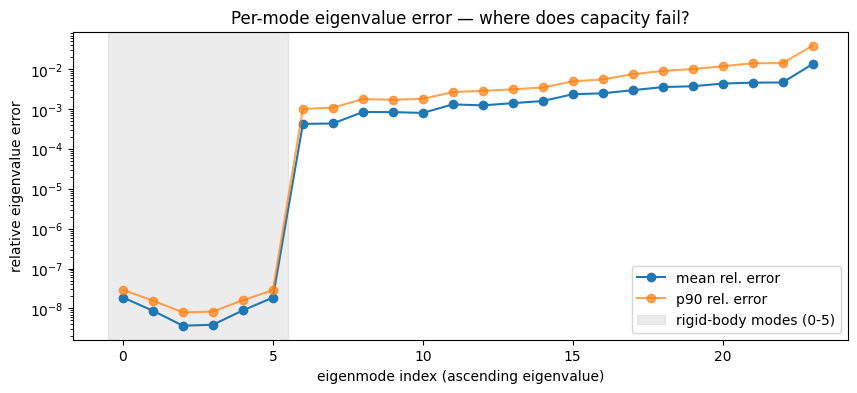

Rel. error, softest physical mode (idx 6): 0.0004258167614481677
Rel. error, stiffest mode (idx 23):        0.01342721164887184


In [52]:
# Eigendecompose both matrices (ascending order). Modes 0-5 are the
# constructed rigid-body zeros (exact for K_pred if the hard-constrained
# head is in use); modes 6-23 are the 18 physical modes.
evals_true = torch.linalg.eigvalsh(K_true)   # (N, 24) ascending
evals_pred = torch.linalg.eigvalsh(K_pred)   # (N, 24)

# Relative error per mode index, normalized by that sample's own largest
# eigenvalue (so it's comparable across samples of different physical scale)
scale = evals_true[:, -1:].clamp(min=1e-12)
mode_err = (evals_pred - evals_true).abs() / scale   # (N, 24)

mean_mode_err = mode_err.mean(dim=0)
p90_mode_err  = mode_err.quantile(0.9, dim=0)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(mean_mode_err, marker='o', label='mean rel. error')
ax.plot(p90_mode_err, marker='o', label='p90 rel. error', alpha=0.7)
ax.axvspan(-0.5, 5.5, color='grey', alpha=0.15, label='rigid-body modes (0-5)')
ax.set_xlabel("eigenmode index (ascending eigenvalue)")
ax.set_ylabel("relative eigenvalue error")
ax.set_yscale('log')
ax.legend()
ax.set_title("Per-mode eigenvalue error — where does capacity fail?")
plt.show()

# Explicit callout: is the softest PHYSICAL mode (index 6) disproportionately bad?
print("Rel. error, softest physical mode (idx 6):", mode_err[:, 6].mean().item())
print("Rel. error, stiffest mode (idx 23):       ", mode_err[:, 23].mean().item())

Physical-subspace principal angles (degrees) — 0 = perfectly aligned subspaces:
  mean over all N and 18 angles: 0.0075637455598400885
  worst angle per sample, mean : 0.13463675813506554


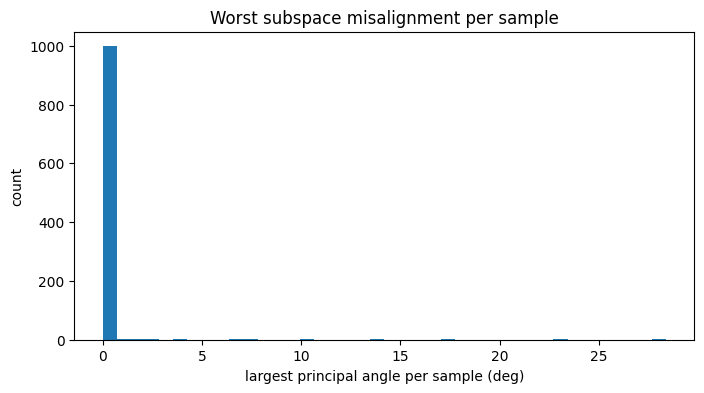

In [53]:
_, evecs_true = torch.linalg.eigh(K_true)
_, evecs_pred = torch.linalg.eigh(K_pred)

# Restrict to the 18 physical modes (skip the 6 constructed-null ones,
# which are meaningless subspace-wise for K_pred since they're fixed by T)
V_true = evecs_true[:, :, 6:]   # (N, 24, 18)
V_pred = evecs_pred[:, :, 6:]

# Principal angles between the two 18-dim subspaces via SVD of V_true^T V_pred
M = V_true.transpose(-1, -2) @ V_pred          # (N, 18, 18)
svals = torch.linalg.svdvals(M)                  # (N, 18), cos(principal angles), descending
principal_angles_deg = torch.rad2deg(torch.arccos(svals.clamp(-1, 1)))

print("Physical-subspace principal angles (degrees) — 0 = perfectly aligned subspaces:")
print("  mean over all N and 18 angles:", principal_angles_deg.mean().item())
print("  worst angle per sample, mean :", principal_angles_deg.max(dim=1).values.mean().item())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(principal_angles_deg.max(dim=1).values.numpy(), bins=40)
ax.set_xlabel("largest principal angle per sample (deg)")
ax.set_ylabel("count")
ax.set_title("Worst subspace misalignment per sample")
plt.show()

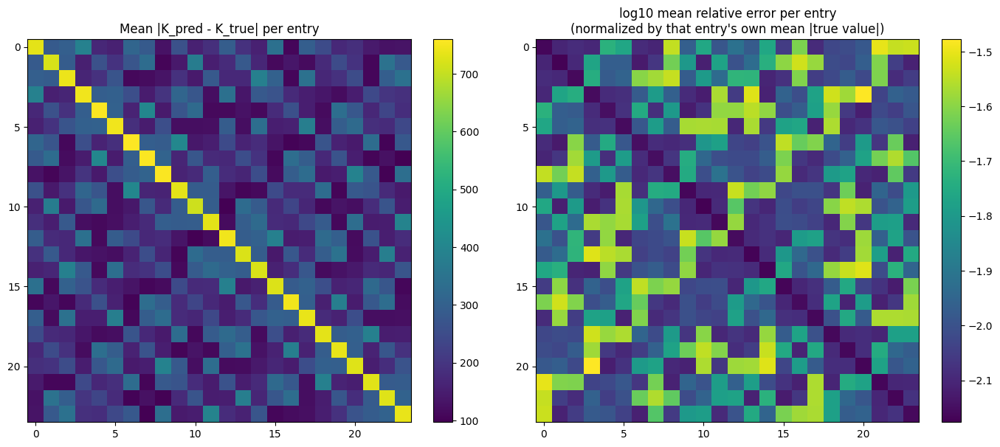

In [54]:
# Absolute error per entry, averaged over samples (in the matrix's own units)
mean_abs_entry_err = diff.abs().mean(dim=0)   # (24, 24)

# Relative error per entry: normalize by that ENTRY's own typical magnitude
# across the dataset (not the whole matrix's norm) -- reveals which specific
# positions are hard even if they're individually small
entry_scale = K_true.abs().mean(dim=0).clamp(min=1e-6)   # (24, 24)
mean_rel_entry_err = (diff.abs().mean(dim=0)) / entry_scale

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
im0 = axes[0].imshow(mean_abs_entry_err.numpy(), cmap='viridis')
axes[0].set_title("Mean |K_pred - K_true| per entry")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(np.log10(mean_rel_entry_err.numpy() + 1e-8), cmap='viridis')
axes[1].set_title("log10 mean relative error per entry\n(normalized by that entry's own mean |true value|)")
plt.colorbar(im1, ax=axes[1], fraction=0.046)
plt.tight_layout(); plt.show()

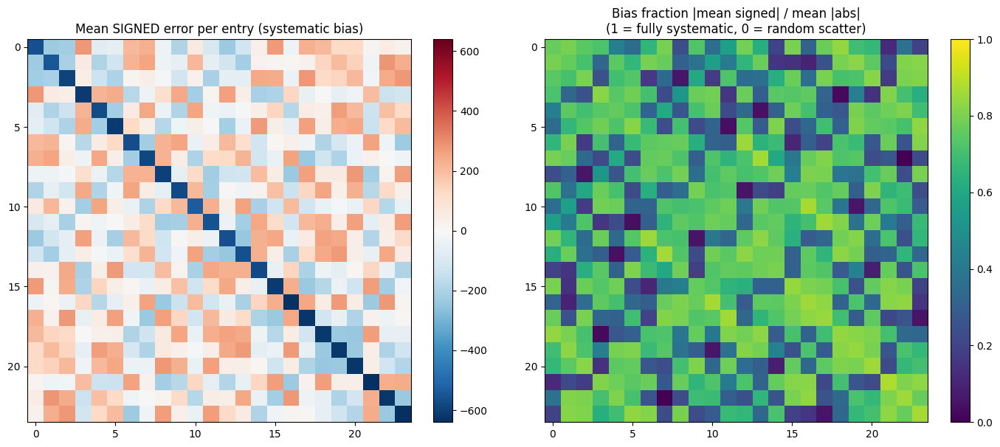

Overall mean bias fraction: 0.5672053730454713


In [55]:
mean_signed_entry_err = diff.mean(dim=0)               # (24,24) -- signed, not abs
bias_fraction = mean_signed_entry_err.abs() / (diff.abs().mean(dim=0).clamp(min=1e-9))
# ~1 means errors on that entry are almost always the same sign (biased);
# ~0 means they average out (random/unbiased scatter)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
vmax = mean_signed_entry_err.abs().max().item()
im0 = axes[0].imshow(mean_signed_entry_err.numpy(), cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[0].set_title("Mean SIGNED error per entry (systematic bias)")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(bias_fraction.numpy(), cmap='viridis', vmin=0, vmax=1)
axes[1].set_title("Bias fraction |mean signed| / mean |abs|\n(1 = fully systematic, 0 = random scatter)")
plt.colorbar(im1, ax=axes[1], fraction=0.046)
plt.tight_layout(); plt.show()

print("Overall mean bias fraction:", bias_fraction[entry_scale > entry_scale.max()*1e-3].mean().item())

Diagonal entries:     mean rel err = 0.0069
Off-diagonal entries: mean rel err = 0.0143


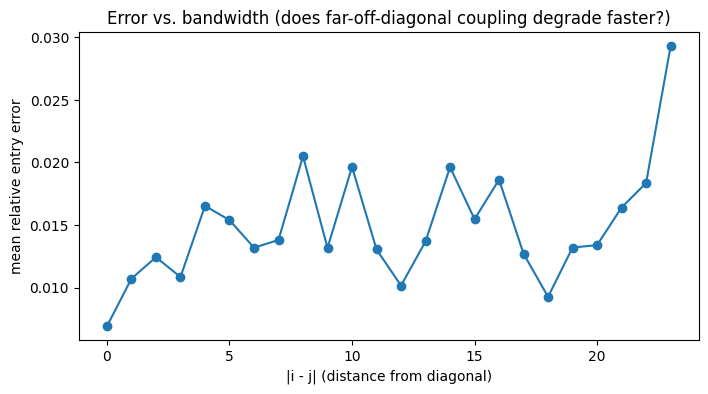

In [56]:
diag_mask = torch.eye(24, dtype=torch.bool)
diag_rel_err = mean_rel_entry_err[diag_mask]
offdiag_rel_err = mean_rel_entry_err[~diag_mask]

print(f"Diagonal entries:     mean rel err = {diag_rel_err.mean():.4f}")
print(f"Off-diagonal entries: mean rel err = {offdiag_rel_err.mean():.4f}")

# Error as a function of |i - j| (bandwidth from the diagonal)
idx = torch.arange(24)
dist_from_diag = (idx.unsqueeze(0) - idx.unsqueeze(1)).abs()   # (24,24)
max_dist = dist_from_diag.max().item()

err_by_dist = [mean_rel_entry_err[dist_from_diag == k].mean().item() for k in range(max_dist + 1)]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(max_dist + 1), err_by_dist, marker='o')
ax.set_xlabel("|i - j| (distance from diagonal)")
ax.set_ylabel("mean relative entry error")
ax.set_title("Error vs. bandwidth (does far-off-diagonal coupling degrade faster?)")
plt.show()

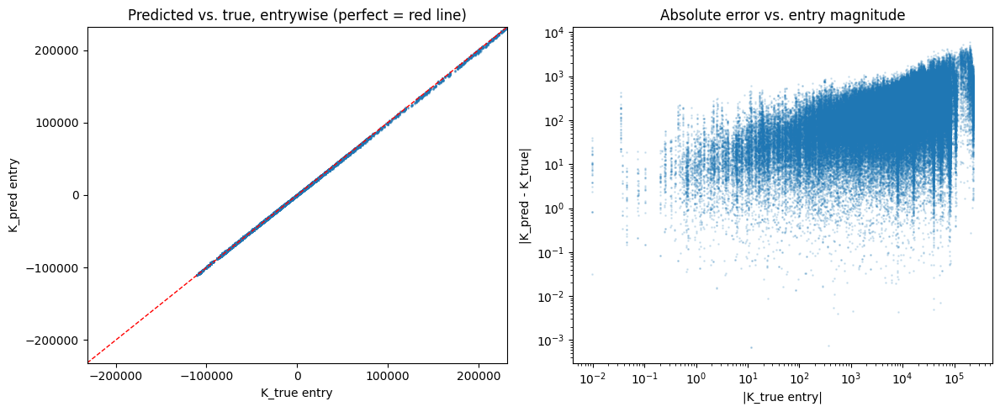

In [57]:
true_flat = K_true.reshape(-1).numpy()
pred_flat = K_pred.reshape(-1).numpy()
abs_err_flat = diff.abs().reshape(-1).numpy()

# subsample for plotting if N*24*24 is large
n_plot = min(200_000, len(true_flat))
idx_sub = np.random.choice(len(true_flat), n_plot, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(true_flat[idx_sub], pred_flat[idx_sub], s=1, alpha=0.15)
lim = np.percentile(np.abs(true_flat), 99.5)
axes[0].plot([-lim, lim], [-lim, lim], 'r--', lw=1)
axes[0].set_xlim(-lim, lim); axes[0].set_ylim(-lim, lim)
axes[0].set_xlabel("K_true entry"); axes[0].set_ylabel("K_pred entry")
axes[0].set_title("Predicted vs. true, entrywise (perfect = red line)")

axes[1].scatter(np.abs(true_flat[idx_sub]), abs_err_flat[idx_sub], s=1, alpha=0.15)
axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_xlabel("|K_true entry|"); axes[1].set_ylabel("|K_pred - K_true|")
axes[1].set_title("Absolute error vs. entry magnitude")
plt.tight_layout(); plt.show()

In [58]:
K_true[0,:,:].shape

torch.Size([24, 24])

In [59]:
#retrieving the data for the first sample (d_batch)
compute_nn_cutcell_stiffness(    d_cut=d_norm, nu_cut=nu_cut, nn_engine=nn_engine,
    material=case.material, partial_indices=queso_active, h_ref=h_ref,)

([tensor([[ 6.8996e+01,  1.4473e+01, -7.5956e+00,  9.1866e+00,  7.3889e+01,
            1.9052e+01, -8.8244e+01, -4.2287e+01,  1.2006e+02,  1.0256e+02,
           -4.5605e+00, -1.0370e+01,  1.2899e+01,  1.7480e+01,  1.6345e+01,
            2.5716e+01,  1.3263e+02,  1.3712e+01, -3.3399e+02, -2.8103e+02,
           -2.4532e+02,  2.0288e+02,  8.9406e+01,  9.4117e+01],
          [ 1.4473e+01,  2.1914e+01, -4.5539e+00,  4.1467e+01,  3.5679e+01,
            4.9531e+00,  8.2360e+00, -1.8718e-02,  6.5243e+01,  1.2292e+00,
            2.3360e+01,  1.0552e+01,  8.2949e+00,  2.0166e+01,  7.9364e+00,
            4.9775e+01,  1.9641e+02,  7.2599e+01, -2.2817e+02, -3.4608e+02,
           -2.0820e+02,  1.0470e+02,  4.8570e+01,  5.1470e+01],
          [-7.5956e+00, -4.5541e+00,  5.4745e+01, -4.8337e+00,  1.1033e+02,
            2.3047e+01,  1.0831e+02, -4.3924e+00,  8.1228e+01,  7.0817e+01,
            1.2574e+00,  4.7060e+01, -3.9723e+00,  2.6826e+00,  1.6296e+01,
            3.8741e+01,  2.9609e+01,

In [60]:
K_pred.shape

torch.Size([1016, 24, 24])

In [61]:
np.sort(np.linalg.eigvals(K_pred[0,:,:].cpu().numpy()+ 1e-3 * np.eye(24)).real)

array([8.12846451e-04, 9.68337717e-04, 9.68337717e-04, 1.01678892e-03,
       1.08675601e-03, 1.17982642e-03, 1.39251346e-01, 5.85423425e+00,
       1.15436035e+01, 5.92990682e+01, 7.58262671e+01, 1.38632035e+02,
       2.37492378e+02, 3.13344827e+02, 4.96602933e+02, 5.60768993e+02,
       7.40654716e+02, 1.48550500e+03, 5.80479515e+03, 6.47785365e+03,
       1.03709565e+04, 1.12575890e+04, 1.27257080e+04, 3.61744196e+04])

In [62]:
dL = (L_pred - L_ref).reshape(len(L_pred), -1)
dK = (K_pred - K_ref).reshape(len(K_pred), -1)

corr = torch.corrcoef(
    torch.stack([
        dL.norm(dim=1),
        dK.norm(dim=1)
    ])
)

print(corr)

NameError: name 'L_pred' is not defined

In [ ]:
import torch
import matplotlib.pyplot as plt

with torch.no_grad():
    M = K_true.shape[0]
    reg = 1e-3 * np.eye(24)

    bias_sum = np.zeros((24, 24))

    for i in range(M):
        try:
            L_ref = np.linalg.cholesky(K_true[i] + reg)
            L_pred = np.linalg.cholesky(K_pred[i] + reg)
            dL = (L_pred - L_ref).reshape(len(L_pred), -1)
            dK = (K_pred[i] - K_true[i]).reshape(len(K_pred[i]), -1)

            corr = np.corrcoef(
                np.stack([
                    np.linalg.norm(dL, axis=1),
                    np.linalg.norm(dK, axis=1)
                ])
            )

            print(corr[0, 1])
        except Exception as e:
            pass

C:\Users\z0058p1u\AppData\Local\Temp\ipykernel_6364\1279086113.py:12: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  L_ref = np.linalg.cholesky(K_true[i] + reg)
C:\Users\z0058p1u\AppData\Local\Temp\ipykernel_6364\1279086113.py:13: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  L_pred = np.linalg.cholesky(K_pred[i] + reg)


0.5735817191787599
0.548255626259909
0.7941043190520538
0.8099438908800707
0.1749678592776809
0.610481741397479
0.45418479460304506
0.35495626408904113
0.4126869488702721
0.8357656227262359
0.8541050158474714
0.8421553495365082
0.7923400141447877
0.40443806682961264
0.7376808618761236
0.18425551599639697
0.3437531919941771
0.5875181430220128
0.732553276111662
0.6477800500430807
0.5977674338840736
0.3398111775382875
0.16082531258701868
0.46888139431312686
0.15880369447820983
0.7288026625722317
0.2810750087504549
0.6489611319669059
0.5146255792050157
0.2710204076690105
0.8746020326226601
0.7525034431339276
0.9473450443444004
0.8913901569637926
0.700100212839501
0.2588313545298337
0.7522937831477526
0.46579988557803254
0.9270577011909007
0.8430197405211344
0.6998171480535238
0.4199670731969046
0.8191392118407627
0.30557531851520714
0.4702199016901731
0.24299437459623444
0.48711104609723466
0.6719033966915294
0.38232478513575535
0.8922932779338281
0.24269329130715453
0.937235967874061
0.78

TypeError: Invalid shape (24,) for image data

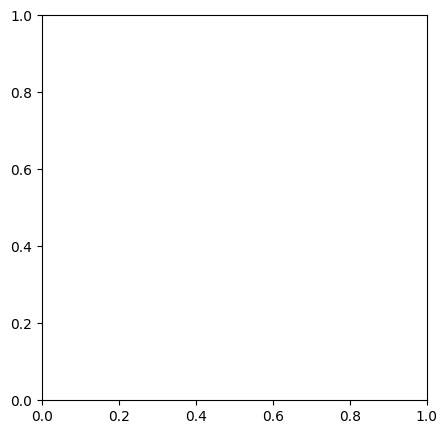

In [ ]:
mean_bias_L = (L_pred - L_ref).mean(0).cpu()

plt.figure(figsize=(6,5))
plt.imshow(mean_bias_L)
plt.colorbar()
plt.title("Mean bias in Cholesky factor")
plt.show()

Fraction of (sample, entry) pairs where K_true ~ 0: 0.0759
Mean |K_pred| at those positions: 42.9289
vs. mean |K_true| overall: 24323.6068
  -> ratio (should be << 1 if sparsity is respected): 0.0018


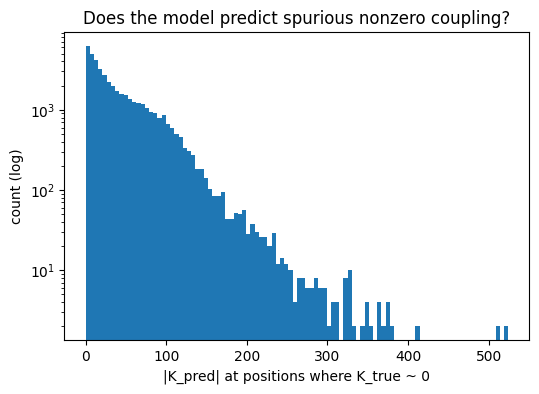

In [ ]:
zero_thresh = entry_scale.max() * 1e-3   # entries below this in K_true are "structurally zero" for this check

true_is_zero = K_true.abs() < zero_thresh.item()
pred_at_zero_positions = K_pred[true_is_zero].abs()

print(f"Fraction of (sample, entry) pairs where K_true ~ 0: {true_is_zero.float().mean():.4f}")
print(f"Mean |K_pred| at those positions: {pred_at_zero_positions.mean():.4f}")
print(f"vs. mean |K_true| overall: {K_true.abs().mean():.4f}")
print(f"  -> ratio (should be << 1 if sparsity is respected): {(pred_at_zero_positions.mean() / K_true.abs().mean()):.4f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(pred_at_zero_positions.numpy(), bins=100, log=True)
ax.set_xlabel("|K_pred| at positions where K_true ~ 0")
ax.set_ylabel("count (log)")
ax.set_title("Does the model predict spurious nonzero coupling?")
plt.show()

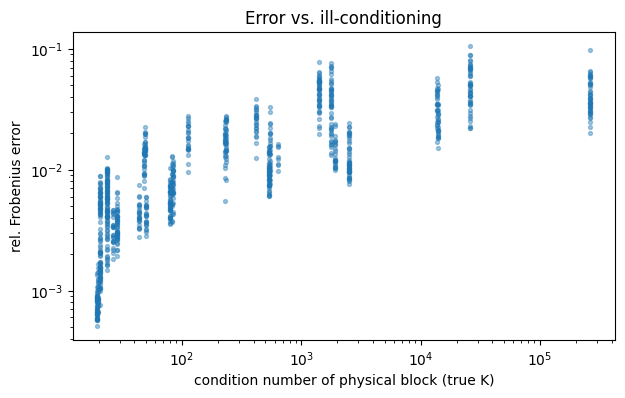

Correlation(log condition number, log rel error): 0.776


In [ ]:
cond_true = evals_true[:, -1] / evals_true[:, 6].clamp(min=1e-12)  # stiffest / softest-physical

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(cond_true, rel_err, s=8, alpha=0.4)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel("condition number of physical block (true K)")
ax.set_ylabel("rel. Frobenius error")
ax.set_title("Error vs. ill-conditioning")
plt.show()

corr = np.corrcoef(torch.log(cond_true).numpy(), torch.log(rel_err.clamp(min=1e-12)).numpy())[0,1]
print(f"Correlation(log condition number, log rel error): {corr:.3f}")